# YZ50 — Week 12: Training GPT-2 (124M) from Scratch and Evaluating It

- **From one corpus file to a token pipeline.** Week 11 trained on 338K tokens of Tiny Shakespeare held in memory. This week the training data is **40 million GPT-2 tokens of FineWeb-Edu**, streamed, tokenized once, and stored as memory-mapped `uint16` **shards**, with a **validation split of separate documents**.

- **Measuring generalization during training.** The loss on the training batch is only half of the picture. At fixed intervals I measure the **validation loss** on a fixed set of held-out batches, and I let the model **write text** from the same prompts, so that I can see what a lower loss means in practice.

- **A real training run.** The Week 11 GPT-2, with all of its settings, now trains for **2,400 optimizer steps (39.3M tokens, 51 minutes)** on my laptop GPU, with checkpoints that can be resumed.

- **HellaSwag.** A benchmark of 10,042 sentence completions with four candidate endings. A language model can answer it without any fine-tuning: the ending it finds most likely is its answer. I run the **same evaluation code on my model and on OpenAI's GPT-2 (124M)**, which has the same architecture but was trained on far more data.

In this final week, I follow the last part of Karpathy's GPT-2 lecture (from 3:10:21). The model starts from **random weights**; OpenAI's pretrained weights are only loaded as a separate reference for the comparison. The long-running parts are scripts (`prepare_data.py`, `train.py`, `evaluate_hellaswag.py`); this notebook documents the workflow, verifies it, and analyzes their saved results. Nothing here restarts the training run.

## Learning Objectives

1. Prepare a pretraining dataset: stream it, tokenize it, split it **by document**, and write shards that a loader can read without loading them into memory.
2. Write a data loader whose targets are correct across shard boundaries, and test it on the edge cases.
3. Train the full 124M GPT-2 within a fixed hardware and time budget, and record what actually happened: steps, tokens, time, throughput, and memory.
4. Compare training and validation loss with **the same procedure**, and read the gap between them.
5. Follow how generated text changes over training without overstating it.
6. Implement HellaSwag scoring transparently and compare two models fairly: same examples, tokenizer, formatting, scoring, and precision.
7. Explain where the difference between my model and OpenAI's GPT-2 comes from.

## Connecting Weeks 10–12

| Week | What I built | What it showed |
|---|---|---|
| 10 | GPT-2 (124M) module; loaded OpenAI's weights into it; sampling; one-batch overfitting | The architecture is right: my logits match Hugging Face's |
| 11 | Data loader, weight tying, initialization, TF32/BF16/SDPA/padded vocabulary, AdamW groups, clipping, warmup + cosine, gradient accumulation | The training step is correct and twice as fast as float32 on this GPU |
| **12** | **FineWeb-Edu shards, validation, generation during training, checkpointing, a 51-minute training run, HellaSwag** | **What 39M tokens of training gives the same architecture, and how far it is from OpenAI's model** |

The model code is the Week 10/11 code, collected in `gpt2_model.py` without changes, so the model trained here is the model I tested in the previous two weeks.

In [1]:
from pathlib import Path
import sys
import json
import math
import re
import statistics
import textwrap
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.nn import functional as F
import tiktoken
from IPython.display import display, Markdown

# works from the repository root and from week-12/
week_dir = Path.cwd() if (Path.cwd() / 'gpt2_model.py').exists() else Path.cwd() / 'week-12'
sys.path.insert(0, str(week_dir))
from gpt2_model import (GPT, GPTConfig, GPT2_VOCAB_SIZE, PADDED_VOCAB_SIZE, build_model, configure_optimizers,
                        from_pretrained, generate, get_lr, init_gpt2_weights, set_tf32)
from train import ShardedDataLoader, estimate_loss, PROMPTS
import evaluate_hellaswag as hs
import sanity_checks

data_dir = week_dir / 'data' / 'fineweb_edu'
results_dir = week_dir / 'results'
run_dir = results_dir / 'main'
ckpt_dir = week_dir / 'checkpoints' / 'main'
seed = 1337
device = 'cuda' if torch.cuda.is_available() else 'cpu'
enc = tiktoken.get_encoding('gpt2')
BLUE, ORANGE, GREY, GREEN = '#2a78d6', '#eb6834', '#9a9a94', '#2e9e6a'

import datasets, transformers
print('PyTorch:', torch.__version__, '| tiktoken:', tiktoken.__version__, '| datasets:', datasets.__version__, '| transformers:', transformers.__version__)
print('device:', device)
if device == 'cuda':
    props = torch.cuda.get_device_properties(0)
    print(f'GPU: {props.name} | memory: {props.total_memory / 2**30:.1f} GiB | compute capability: {props.major}.{props.minor} | BF16: {torch.cuda.is_bf16_supported()}')
assert (data_dir / 'metadata.json').exists() and (run_dir / 'summary.json').exists()

PyTorch: 2.14.0+cu126 | tiktoken: 0.14.0 | datasets: 4.8.5 | transformers: 4.57.1
device: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU | memory: 6.0 GiB | compute capability: 8.6 | BF16: True


### How the Work Is Split Between Scripts and This Notebook

| File | Role | Run time on my laptop |
|---|---|---|
| `gpt2_model.py` | Week 10/11 GPT-2, initialization, AdamW groups, LR schedule, sampling | — |
| `prepare_data.py` | streams FineWeb-Edu and writes the token shards | 13 min |
| `train.py` | sharded loader, training loop, validation, generation, checkpoints, resume | 51 min of training |
| `evaluate_hellaswag.py` | HellaSwag scoring for either model, and the paired comparison | 5 min per model |
| `pilot.py` | batch-shape benchmark and learning-rate pilot | 3 + 11 min |
| `sanity_checks.py` | loader, model, checkpoint/resume, and HellaSwag checks | 4 min |

The commands are printed in the cells where they belong, but **they are not executed here**. A few small analyses that need the GPU (validation loss of OpenAI's GPT-2, generation statistics, HellaSwag over the checkpoints) are computed once and cached in `results/`; later runs of this notebook only read them.

# 1. FineWeb-Edu'dan küçük bir parça (birkaç on milyon token yeterli) ya da kendi Türkçe metnini GPT-2 tokenizer'ıyla token'la. Token'ları dosyalara böl ve data loader'ını bu dosyalardan okuyacak hâle getir. Bir dosyayı doğrulama için ayır.

## 1. Dataset Preparation and Tokenization

### Source

**FineWeb-Edu** is a subset of Common Crawl web pages that a classifier rated as educational. I use its `sample-10BT` configuration, a random sample of about 10 billion GPT-2 tokens stored in 14 parquet files (26.6 GiB). I take a bounded part of it with `datasets` **streaming**, so only the parts of the files that are read get downloaded. The dataset revision is pinned and recorded.

**The files are ordered by crawl date.** Before preparing the data I read the first 3,000 documents of three files: file 000 contained only the crawl `CC-MAIN-2013-20`, and file 013 only `CC-MAIN-2023-06`. Taking the first 40M tokens of the stream would therefore have given me 2013 web pages only. Instead, `prepare_data.py` reads the 14 files **round-robin**, one document from each in turn. Each file is still read from its beginning, so this is a deterministic sample spread over the crawls, not a uniform random sample of the dataset.

### Tokenization and Format

Every document is encoded with `tiktoken.get_encoding("gpt2")` and **prefixed with `<|endoftext|>` (ID 50256)**, so consecutive documents are separated by it and the model sees where a new document starts. All IDs are below \(50257 < 2^{16}=65536\), so they fit in **`uint16`**: two bytes per token instead of eight for `int64`, and 80 MB for the whole corpus.

### The Train/Validation Split

The split is made per **document**, before tokenization, from the document's FineWeb `id`:

\[
\text{split}(d)=\begin{cases}\text{val} & \dfrac{\operatorname{int}\big(\operatorname{sha256}(\texttt{"1337:"}+\texttt{id}_d)_{[0:8]}\big)}{2^{64}} < 0.025\\[2mm]\text{train} & \text{otherwise}\end{cases}
\]

- The same document always gets the same split, independent of the order in which documents arrive.
- A document is never cut between the two splits. Each split has its **own token stream and its own shard files**; a document that crosses a shard limit continues in the next shard of the same split.
- \(0.025\approx 1/41\) makes both splits fill at about the same rate for the budgets of **40M training and 1M validation tokens**, so validation documents come from the same range of the stream as training documents.
- Once a split reaches its budget, further documents assigned to it are **dropped, never moved to the other split**. The document that reaches the budget is cut at the budget.

In [2]:
print('command (already run):')
print('  python week-12/prepare_data.py --train_tokens 40_000_000 --val_tokens 1_000_000 --val_fraction 0.025 --shard_size 5_000_000\n')
meta = json.loads((data_dir / 'metadata.json').read_text(encoding='utf-8'))
print(f"source: {meta['source_dataset']} / {meta['subset']} @ revision {meta['revision'][:12]} | prepared {meta['preparation_date_utc']} in {meta['preparation_seconds'] / 60:.1f} min")
print(f"tokenizer: {meta['tokenizer']} | dtype {meta['dtype']} | seed {meta['seed']} | val_fraction {meta['val_fraction']}")
rows = ['| Split | Tokens | Documents | Tokens per document | Shards | Shard sizes |', '|---|---:|---:|---:|---:|---|']
for split, s in meta['splits'].items():
    sizes = sorted({sh['tokens'] for sh in s['shards']})
    rows.append(f"| {split} | {s['tokens']:,} | {s['documents']:,} | {s['tokens'] / s['documents']:,.0f} | {len(s['shards'])} | {', '.join(f'{v:,}' for v in sizes)} |")
display(Markdown('\n'.join(rows)))
print(f"documents streamed: {meta['documents_streamed']:,} | dropped because their split was full: {meta['documents_skipped_split_full']}")
print(f"identical texts in both splits: {meta['exact_text_duplicates_across_splits']}")
assert meta['splits']['train']['tokens'] == 40_000_000 and meta['splits']['val']['tokens'] == 1_000_000

command (already run):
  python week-12/prepare_data.py --train_tokens 40_000_000 --val_tokens 1_000_000 --val_fraction 0.025 --shard_size 5_000_000

source: HuggingFaceFW/fineweb-edu / sample-10BT @ revision 87f09149ef47 | prepared 2026-11-06T21:26:01+00:00 in 13.3 min
tokenizer: tiktoken gpt2 (encode_ordinary), <|endoftext|> = 50256 prepended to every document | dtype uint16 | seed 1337 | val_fraction 0.025


| Split | Tokens | Documents | Tokens per document | Shards | Shard sizes |
|---|---:|---:|---:|---:|---|
| train | 40,000,000 | 38,696 | 1,034 | 8 | 5,000,000 |
| val | 1,000,000 | 865 | 1,156 | 1 | 1,000,000 |

documents streamed: 39,936 | dropped because their split was full: {'val': 133, 'train': 242}
identical texts in both splits: 0


crawl dumps: 21 in total, 21 in train, 20 in val, from CC-MAIN-2013-20 to CC-MAIN-2024-10
documents per source file: train 2755-2772, val 55-71


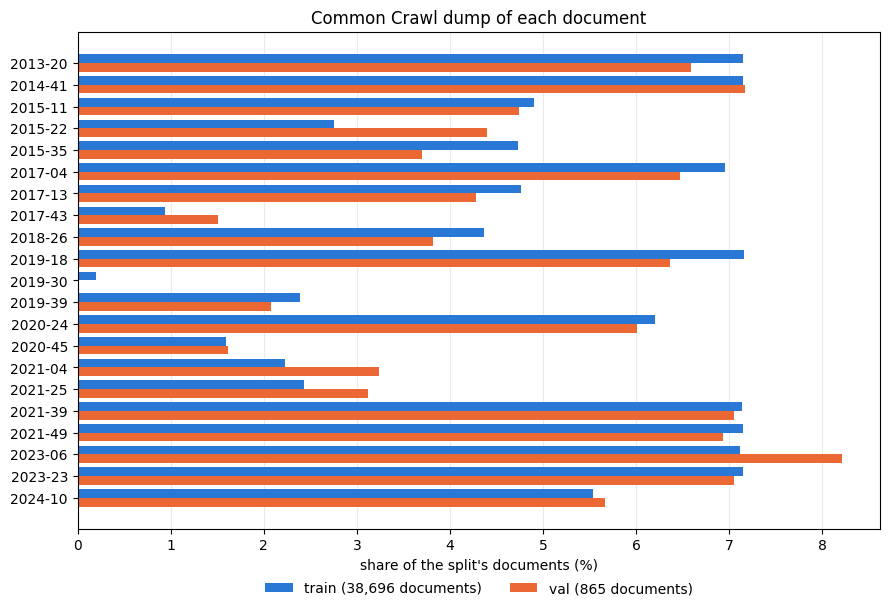

In [3]:
dumps = sorted(set(meta['splits']['train']['crawl_dumps']) | set(meta['splits']['val']['crawl_dumps']))
share = {split: np.array([meta['splits'][split]['crawl_dumps'].get(d, 0) for d in dumps]) / meta['splits'][split]['documents']
         for split in ['train', 'val']}
files_per = {split: list(meta['splits'][split]['documents_per_source_file'].values()) for split in ['train', 'val']}
print(f"crawl dumps: {len(dumps)} in total, {sum(share['train'] > 0)} in train, {sum(share['val'] > 0)} in val, from {dumps[0]} to {dumps[-1]}")
print(f"documents per source file: train {min(files_per['train'])}-{max(files_per['train'])}, val {min(files_per['val'])}-{max(files_per['val'])}")

fig, ax = plt.subplots(figsize=(9, 6.2))
y = np.arange(len(dumps))
ax.barh(y - 0.2, share['train'] * 100, height=0.4, color=BLUE, label=f"train ({meta['splits']['train']['documents']:,} documents)")
ax.barh(y + 0.2, share['val'] * 100, height=0.4, color=ORANGE, label=f"val ({meta['splits']['val']['documents']:,} documents)")
ax.set_yticks(y, [d.replace('CC-MAIN-', '') for d in dumps])
ax.invert_yaxis()
ax.set_xlabel('share of the split\'s documents (%)')
ax.set_title('Common Crawl dump of each document')
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

In [4]:
train_loader = ShardedDataLoader(data_dir, 'train', 8, 256)
val_loader = ShardedDataLoader(data_dir, 'val', 8, 256)
for f, shard in zip(train_loader.files + val_loader.files, train_loader.shards + val_loader.shards):
    print(f'{f.name}: {len(shard):>10,} tokens | {f.stat().st_size / 2**20:5.2f} MiB | {shard.dtype} | {type(shard).__name__}')
first = val_loader.read(0, 40)
print('\nfirst validation tokens:', first[:12].tolist())
print(repr(enc.decode(first.tolist())))
assert first[0] == 50256 # every document starts with <|endoftext|>
assert all(isinstance(s, np.memmap) for s in train_loader.shards + val_loader.shards)
del train_loader, val_loader

fineweb_edu_train_000000.npy:  5,000,000 tokens |  9.54 MiB | uint16 | memmap
fineweb_edu_train_000001.npy:  5,000,000 tokens |  9.54 MiB | uint16 | memmap
fineweb_edu_train_000002.npy:  5,000,000 tokens |  9.54 MiB | uint16 | memmap
fineweb_edu_train_000003.npy:  5,000,000 tokens |  9.54 MiB | uint16 | memmap
fineweb_edu_train_000004.npy:  5,000,000 tokens |  9.54 MiB | uint16 | memmap
fineweb_edu_train_000005.npy:  5,000,000 tokens |  9.54 MiB | uint16 | memmap
fineweb_edu_train_000006.npy:  5,000,000 tokens |  9.54 MiB | uint16 | memmap
fineweb_edu_train_000007.npy:  5,000,000 tokens |  9.54 MiB | uint16 | memmap
fineweb_edu_val_000000.npy:  1,000,000 tokens |  1.91 MiB | uint16 | memmap

first validation tokens: [50256, 464, 9230, 3292, 4073, 12547, 661, 284, 1716, 12387, 10795, 319]
'<|endoftext|>The fur trade caused Native people to become partially dependent on European trade goods, changing their traditional balance between needs and resources. The fur traders introduced alcoho

## 2. Data Shards and the Loader

`ShardedDataLoader` keeps the Week 11 rule and extends it to several files. It treats the shards of one split as **one continuous token stream** with a global position \(p\):

\[
\texttt{buf}=[t_p,\dots,t_{p+BT}],\qquad x=\texttt{buf}[:-1]\ \text{as }(B,T),\qquad y=\texttt{buf}[1:]\ \text{as }(B,T),\qquad p\leftarrow p+BT
\]

- **Shard transitions.** If the \(BT+1\) tokens cross the end of a shard, `read` takes the rest from the next shard. This is correct because `prepare_data.py` wrote the shards of a split as consecutive pieces of one stream: the next token after the end of shard \(k\) really is the first token of shard \(k+1\). No token is dropped at a shard boundary.
- **End of an epoch.** When fewer than \(BT+1\) tokens remain, the loader returns to \(p=0\) and counts an epoch. The tail of fewer than \(BT\) tokens is dropped.
- **Memory.** The shards are opened with `np.load(..., mmap_mode='r')`: only the tokens of the current batch are read from disk, converted to `int64`, and moved to the GPU.
- **State.** The loader's state is just \((p, \text{epoch})\) plus the shard file names and \(B, T\). The checkpoint stores it, and a resumed run refuses a state with different files or a different batch shape.
- **Isolation.** A train loader only opens files named `*_train_*` and a val loader only `*_val_*`, and both lists are checked against `metadata.json`.

The checks below are the ones from `sanity_checks.py`, run here on the real shards. First, synthetic shards of 100, 37 and 64 tokens whose values equal their position in the stream, so that every expected batch is known exactly; then the 40M-token training split.

In [5]:
sanity_checks.check_loader(data_dir)


== sharded data loader ==
synthetic shards [100, 37, 64]: 12 batches per epoch, 2 cross a shard boundary, 8 tail tokens dropped at the wrap


real shards: train 40,000,000 tokens in 8 files, val 1,000,000 in 1; 38696 + 865 documents, 0 shared ids, 1 of 865 val documents open with the same 32 tokens as a train document
Loader checks passed.


### A Near-Duplicate Across the Split

The loader check counts validation documents whose **first 32 tokens** also open a training document. Different FineWeb ids and different texts do not exclude this: web pages of the same site share headers and templates. The count is not zero, so I looked at the case.

In [6]:
def split_documents(split):
    loader = ShardedDataLoader(data_dir, split, 1, 8)
    tokens = loader.read(0, loader.n_tokens)
    starts = np.flatnonzero(tokens == 50256)
    return [tokens[a + 1:b] for a, b in zip(starts, list(starts[1:]) + [len(tokens)])]

train_docs, val_docs = split_documents('train'), split_documents('val')
openings = {}
for i, d in enumerate(train_docs):
    if len(d) >= 32:
        openings.setdefault(d[:32].tobytes(), []).append(i)
for j, v in enumerate(val_docs):
    matches = openings.get(v[:32].tobytes(), []) if len(v) >= 32 else []
    for i in matches[:1]:
        common = next((k for k in range(min(len(v), len(train_docs[i]))) if v[k] != train_docs[i][k]), min(len(v), len(train_docs[i])))
        print(f'val document {j}: {len(v)} tokens, opening shared with {len(matches)} training documents; '
              f'longest common prefix {common} tokens ({common / len(v):.0%} of the document, {common / 1e6:.4%} of the val tokens)')
        print('shared part:', repr(enc.decode(v[:common].tolist())[:300]), '...')
        print('val continues:', repr(enc.decode(v[common:common + 30].tolist())))
        print('train continues:', repr(enc.decode(train_docs[i][common:common + 30].tolist())))
del train_docs, val_docs, openings

val document 339: 595 tokens, opening shared with 3 training documents; longest common prefix 124 tokens (21% of the document, 0.0124% of the val tokens)
shared part: "ReadWriteThink couldn't publish all of this great content without literacy experts to write and review for us. If you've got lessons plans, videos, activities, or other ideas you'd like to contribute, we'd love to hear from you.\nFind the latest in professional publications, learn new techniques and " ...
val continues: 'Exploring Free Speech and Persuasion with Nothing But the Truth\n|Grades||6 – 8|\n|Lesson Plan Type||Standard'
train continues: '|Grades||6 – 12|\n|Lesson Plan Type||Recurring Lesson|\n|Estimated Time||50 minutes (or'


**Reading the data checks.** The training split has exactly 40,000,000 tokens in eight 5M-token shards, and the validation split 1,000,000 tokens in one shard. The two splits share **no document id and no identical text**, and every loader property holds on the real files: one-token shift, contiguity across all eight shard files, complete in-order coverage of an epoch. The sample covers **21 crawl dumps from 2013 to 2024**, with each of the 14 source files contributing almost the same number of documents.

The single shared opening is a **site boilerplate header**: one ReadWriteThink page in validation begins with the same 124-token "contribute to us" paragraph as three ReadWriteThink pages in training, and then continues with different content. This is a property of web text, not a broken split, and it touches 0.012% of the validation tokens. I keep the document and mention it here rather than remove it after the fact.

# 3. Hafta 11'de hızlandırdığın GPT-2'yi donanımına göre belli bir süre eğit. Kaç token gördüğünü, saniyede kaç token işlediğini ve son loss'u yaz. Eğitim ilerledikçe ürettiği metin nasıl değişiyor?

## 3. Training Configuration

### What Is Kept from Week 11

| Component | Setting |
|---|---|
| Architecture | GPT-2 124M: 12 layers, 12 heads, 768 dimensions, context up to 1,024, fused `c_attn`, tanh GELU, pre-LayerNorm |
| Vocabulary | GPT-2 BPE (50,257 tokens), padded to **50,304** in the embedding/output matrix |
| Initialization | **random**, seed 1337: \(\mathcal N(0,0.02^2)\), residual projections \(0.02/\sqrt{2\cdot12}\), weight tying |
| Precision and kernels | TF32 matmuls, **BF16 autocast**, `F.scaled_dot_product_attention` (memory-efficient kernel; this Windows build has no Flash Attention), no `torch.compile` (Triton is missing) |
| Optimizer | AdamW (fused), \(\beta=(0.9, 0.95)\), \(\epsilon=10^{-8}\), weight decay 0.1 on the 2D parameters only, gradient clipping at 1.0 |
| Schedule | linear warmup, then cosine decay to 10% of the peak |
| Batch | gradient accumulation of equal microbatches, loss divided by the number of microbatches |

**How the padding is handled.** The 47 extra rows are never inputs, and as outputs they take part in the softmax of the training and validation loss, as in Week 11. Two places exclude them: `generate` samples only among the 50,257 real tokens (`tiktoken` cannot decode the others), and the comparisons with OpenAI's 50,257-token model restrict both models' logits to the real tokens.

In [7]:
config = GPTConfig() # the configuration train.py uses: vocab 50304, block_size 1024, SDPA
model = GPT(config) # on the CPU, only to count
init_gpt2_weights(model)
n_params = sum(p.numel() for p in model.parameters())
optimizer = configure_optimizers(model, learning_rate=6e-4)
decay, nodecay = optimizer.param_groups
print(config)
print(f'parameters: {n_params:,} (unpadded GPT-2: {n_params - 47 * 768:,}) | tied: {model.lm_head.weight is model.transformer.wte.weight}')
print(f"decayed: {len(decay['params'])} tensors, {sum(p.numel() for p in decay['params']):,} parameters | "
      f"not decayed: {len(nodecay['params'])} tensors, {sum(p.numel() for p in nodecay['params']):,} parameters")
assert n_params == 124_475_904 and (config.n_layer, config.n_head, config.n_embd) == (12, 12, 768)
del model, optimizer

GPTConfig(block_size=1024, vocab_size=50304, n_layer=12, n_head=12, n_embd=768, sdpa=True)
parameters: 124,475,904 (unpadded GPT-2: 124,439,808) | tied: True
decayed: 50 tensors, 124,354,560 parameters | not decayed: 98 tensors, 121,344 parameters


### The Pilot: Batch Shape

The configuration has to fit in 6 GiB. Every candidate below processes **16,384 tokens per optimizer step**; they differ in how the step is divided into microbatches of \(B\times T\) tokens. Each ran as its own `train.py` process for 12 steps on the real shards; the median step time is taken over the last 10. Peak memory is PyTorch's allocated and reserved memory.

    python week-12/pilot.py bench

| Microbatch \(B\times T\) | Accumulation | Step time (ms) | Range (ms) | Tokens/s | Peak allocated (MiB) | Peak reserved (MiB) |
|---|---:|---:|---:|---:|---:|---:|
| 2 × 256 = 512 | 32 | 1,351 | 1,314 – 1,368 | 12,126 | 2,641 | 2,880 |
| 8 × 256 = 2,048 | 8 | 935 | 903 – 954 | 17,525 | 4,017 | 4,598 |
| 16 × 256 = 4,096 | 4 | 1,395 | 1,366 – 1,538 | 11,744 | 5,849 | 7,168 |
| 4 × 512 = 2,048 | 8 | 1,022 | 1,014 – 1,118 | 16,028 | 4,017 | 4,598 |
| 8 × 512 = 4,096 | 4 | 1,450 | 1,434 – 1,544 | 11,301 | 5,850 | 7,166 |
| 2 × 1024 = 2,048 | 8 | 1,123 | 1,116 – 1,173 | 14,584 | 4,021 | 4,598 |
| 4 × 1024 = 4,096 | 4 | 1,423 | 1,299 – 1,616 | 11,513 | 5,845 | 7,166 |

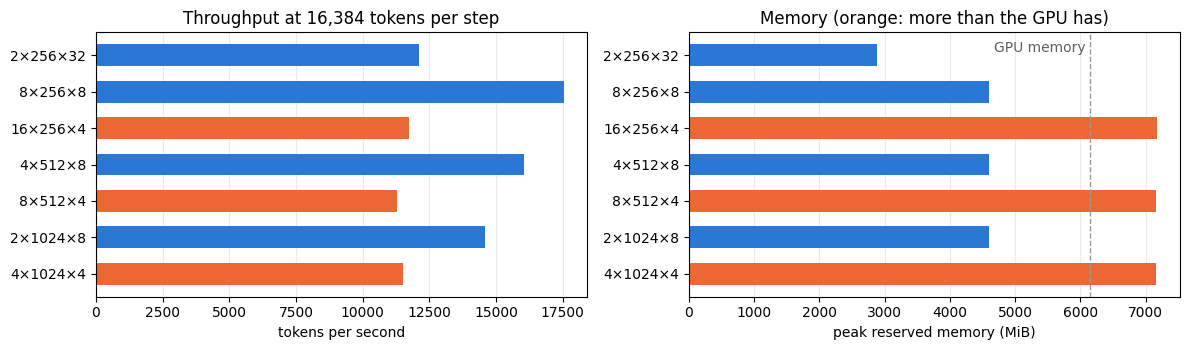

In [8]:
bench = json.loads((results_dir / 'pilot' / 'bench.json').read_text(encoding='utf-8'))
rows = ['| Microbatch \\(B\\times T\\) | Accumulation | Step time (ms) | Range (ms) | Tokens/s | Peak allocated (MiB) | Peak reserved (MiB) |',
        '|---|---:|---:|---:|---:|---:|---:|']
for r in bench:
    rows.append(f"| {r['B']} × {r['T']} = {r['B'] * r['T']:,} | {r['accum']} | {r['median_step_ms']:,.0f} | {r['min_step_ms']:,.0f} – {r['max_step_ms']:,.0f} | "
                f"{r['tokens_per_sec']:,.0f} | {r['peak_allocated_mib']:,.0f} | {r['peak_reserved_mib']:,.0f} |")
display(Markdown('\n'.join(rows)))
gpu_mib = torch.cuda.get_device_properties(0).total_memory / 2**20 if device == 'cuda' else 6144

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
labels = [f"{r['B']}×{r['T']}×{r['accum']}" for r in bench]
colors = [BLUE if r['peak_reserved_mib'] < gpu_mib else ORANGE for r in bench]
axes[0].barh(labels, [r['tokens_per_sec'] for r in bench], color=colors, height=0.6)
axes[0].set_xlabel('tokens per second')
axes[0].set_title('Throughput at 16,384 tokens per step')
axes[1].barh(labels, [r['peak_reserved_mib'] for r in bench], color=colors, height=0.6)
axes[1].axvline(gpu_mib, color=GREY, linestyle='--', linewidth=1)
axes[1].text(gpu_mib, -0.4, 'GPU memory ', color='#5f5f5a', ha='right', va='top')
axes[1].set_xlabel('peak reserved memory (MiB)')
axes[1].set_title('Memory (orange: more than the GPU has)')
for ax in axes:
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.25)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Reading the benchmark.** The three shapes with **8,192-token microbatches** (16×256, 8×512, 4×1024) reserve about 7.0 GiB, more than the GPU's 6 GiB. On Windows the driver does not fail with an out-of-memory error but moves part of the memory to shared system RAM, and these runs fall to about 11.5K tokens/s. Among the shapes that fit, **8×256 is the fastest, 17,525 tokens/s at 3.9 GiB allocated and 4.5 GiB reserved**; longer sequences at the same 4,096 tokens per microbatch are slower (16,028 for 4×512, 14,584 for 2×1024), as the attention cost grows with \(T\). The 2×256 microbatch suggested as a starting point fits easily but wastes the GPU: 12,126 tokens/s.

I chose **8 × 256 × 8 accumulation steps**. A context of 256 tokens is short for language modeling, but it is not a limit for HellaSwag: the longest HellaSwag row (context + ending) is 166 tokens, so no example is truncated.

**These are short, cool-GPU measurements.** In longer runs the laptop GPU heats up and its clock drops; the learning-rate pilot below and the full run measure the sustained speed.

### The Pilot: Learning Rate

The lecture uses a peak of \(6\times10^{-4}\) (GPT-3's value for this size), Week 11 used \(3\times10^{-4}\). I compared both in two runs that differ **only** in `max_lr`:

- the same seed, therefore the **same initial weights** and the **same data order** (checked below);
- the schedule of the planned full run: 100 warmup steps and a cosine horizon of **2,400 steps**, so that steps 100–250 run at nearly the peak rate, where instability would appear;
- 250 steps (4.1M tokens) each, validation every 25 steps on 40 fixed validation batches.

    python week-12/pilot.py lr --micro_batch_size 8 --seq_len 256 --grad_accum_steps 8 --max_steps 2400 --stop_at_step 250

identical start: initial val loss 10.9583 and step-0 training loss 10.9442 in both runs


| Peak LR | val @ 25 | val @ 100 | val @ 150 | val @ 200 | val @ 250 | train-eval @ 250 | max grad norm after warmup | steps clipped | loss spikes |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---|
| 3e-04 | 9.082 | 7.243 | 7.032 | 6.834 | 6.773 | 6.431 | 2.49 | 115 | [83, 113, 142, 160, 164, 193, 206, 215, 219] |
| 6e-04 | 8.509 | 7.119 | 6.986 | 6.800 | 6.714 | 6.383 | 2.40 | 97 | [42, 83, 113, 164, 206, 215, 219] |

spike steps common to both runs: [83, 113, 164, 206, 215, 219]


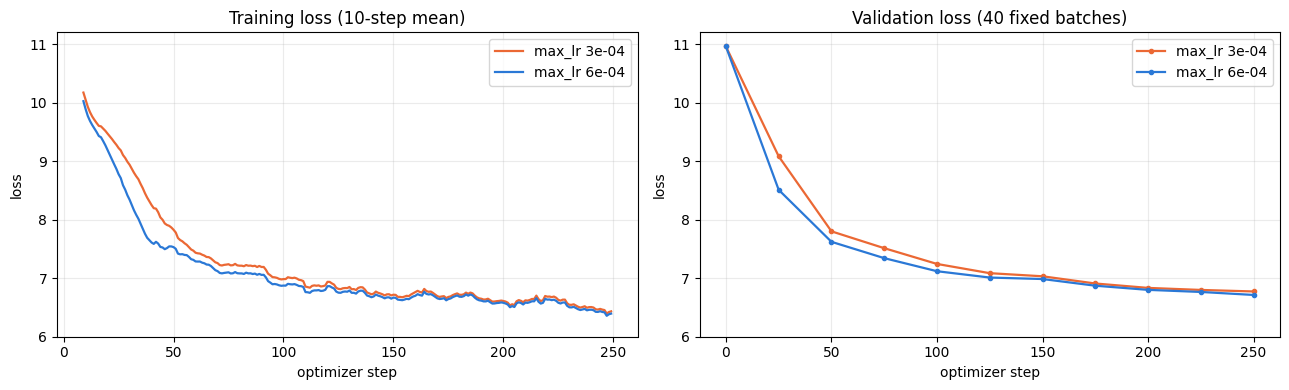

In [9]:
pilot = {lr: json.loads((results_dir / 'pilot' / f'lr_{lr}_8x256x8' / 'history.json').read_text(encoding='utf-8')) for lr in ['3e-04', '6e-04']}
a, b = pilot['3e-04'], pilot['6e-04']
assert a['eval'][0]['val_loss'] == b['eval'][0]['val_loss'] and a['train'][0]['loss'] == b['train'][0]['loss'] # same initial weights
assert [(r['shard'], r['epoch']) for r in a['train']] == [(r['shard'], r['epoch']) for r in b['train']] # same data order
print(f"identical start: initial val loss {a['eval'][0]['val_loss']:.4f} and step-0 training loss {a['train'][0]['loss']:.4f} in both runs")

def spikes(train):
    # steps whose loss is 0.3 above the mean of the 10 steps before
    losses = [r['loss'] for r in train]
    return [r['step'] for i, r in enumerate(train) if i >= 10 and r['loss'] > statistics.mean(losses[i - 10:i]) + 0.3]

rows = ['| Peak LR | val @ 25 | val @ 100 | val @ 150 | val @ 200 | val @ 250 | train-eval @ 250 | max grad norm after warmup | steps clipped | loss spikes |',
        '|---|---:|---:|---:|---:|---:|---:|---:|---:|---|']
for lr, h in pilot.items():
    v = {r['step']: r['val_loss'] for r in h['eval']}
    rows.append(f"| {lr} | {v[25]:.3f} | {v[100]:.3f} | {v[150]:.3f} | {v[200]:.3f} | {v[250]:.3f} | {h['eval'][-1]['train_eval_loss']:.3f} | "
                f"{max(r['grad_norm'] for r in h['train'][100:]):.2f} | {sum(r['grad_norm'] > 1 for r in h['train'])} | {spikes(h['train'])} |")
display(Markdown('\n'.join(rows)))
print('spike steps common to both runs:', sorted(set(spikes(a['train'])) & set(spikes(b['train']))))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for lr, color in [('3e-04', ORANGE), ('6e-04', BLUE)]:
    h = pilot[lr]
    losses = np.array([r['loss'] for r in h['train']])
    smooth = np.convolve(losses, np.ones(10) / 10, mode='valid')
    axes[0].plot(range(9, len(losses)), smooth, color=color, linewidth=1.6, label=f'max_lr {lr}')
    axes[1].plot([r['step'] for r in h['eval']], [r['val_loss'] for r in h['eval']], color=color, marker='o', markersize=3, linewidth=1.6, label=f'max_lr {lr}')
axes[0].set_title('Training loss (10-step mean)')
axes[1].set_title('Validation loss (40 fixed batches)')
for ax in axes:
    ax.set_xlabel('optimizer step')
    ax.set_ylabel('loss')
    ax.set_ylim(6, 11.2)
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

**Reading the learning-rate pilot.** \(6\times10^{-4}\) has the lower validation loss at **every** evaluation. The difference is large during warmup (8.51 against 9.08 at step 25), when the larger rate simply moves faster, and it shrinks to 0.03–0.06 between steps 150 and 250, where both rates are near their peaks. At step 250 it is 6.714 against 6.773, and the training loss measured the same way agrees (6.383 against 6.431).

I looked for signs of instability at the higher rate and found none: after warmup its largest gradient norm was 2.40 (2.49 at \(3\times10^{-4}\)), clipping acted on fewer steps (97 against 115), and the loss spikes occur at the **same steps** in both runs, so they come from particular batches of data, not from the learning rate. I chose \(6\times10^{-4}\) for these reasons, not for speed (the step time does not depend on the learning rate).

The evidence is limited: one seed, and only the first 10% of the planned schedule. The remaining gap is small enough that the end of a full run could look different.

## 4. Training and Checkpointing

### The Run

    python -u week-12/train.py --run_name main --micro_batch_size 8 --seq_len 256 --grad_accum_steps 8 \
      --max_steps 2400 --warmup_steps 100 --max_lr 6e-4 --min_lr 6e-5 \
      --val_every 100 --val_batches 100 --val_batch_size 8 --gen_every 400 --ckpt_every 400 --time_budget_min 58

- \(8\times256\times8 = 16{,}384\) tokens per optimizer step; **2,400 steps = 39,321,600 tokens = 0.98 epochs** of the 40M-token training split, so no training token is used twice.
- The cosine horizon equals the number of steps, so the learning rate ends exactly at its minimum. `--time_budget_min 58` is only a safety limit: training stops after 58 minutes even if the steps are not done.

### Checkpoints

Every 400 steps and at the end, `train.py` saves: model and optimizer state, the completed step, the tokens processed, the training time so far, the full history (losses, learning rates, gradient norms, evaluations, samples), the loader position, the Python/NumPy/PyTorch/CUDA random states, and all arguments. A checkpoint is written in four steps:

1. `torch.save` to `ckpt_step_XXXXXX.pt.tmp`, with `fsync`;
2. **verification**: the file is loaded back and its step, tensor names, finiteness, one weight matrix, and optimizer state count are compared with the model in memory;
3. `os.replace` to the final name, which is atomic;
4. `latest.json` is rewritten (also atomically) to point to it.

A crash at any point leaves either the previous checkpoint marked as latest or the new one complete. Nothing is overwritten and no old checkpoint is deleted before a new one is verified. `--resume latest` checks that the schedule-defining arguments are the same, restores everything, and continues at the next step. A `STOP` file in the checkpoint directory or Ctrl+C ends the run after the current step with a checkpoint.

In [10]:
summary = json.loads((run_dir / 'summary.json').read_text(encoding='utf-8'))
history = json.loads((run_dir / 'history.json').read_text(encoding='utf-8'))
train_hist = history['train']
step_ms = [r['step_ms'] for r in train_hist]
print(f"stop reason: {summary['stop_reason']} | completed optimizer steps: {summary['completed_steps']:,} of {summary['max_steps']:,} | resumes: {len(summary['resumes'])}")
print(f"tokens processed: {summary['tokens_processed']:,} = {summary['completed_steps']:,} steps x {summary['tokens_per_step']:,} "
      f"| unique training tokens available: {summary['train_split_tokens']:,} | epochs: {summary['epochs']:.3f}")
print(f"training time: {summary['train_seconds'] / 60:.1f} min (optimizer steps only; evaluation, sampling and checkpoints excluded)")
print(f"throughput: {summary['tokens_per_sec_train']:,.0f} tokens/s on average | median step {statistics.median(step_ms):,.0f} ms "
      f"= {summary['tokens_per_step'] / statistics.median(step_ms) * 1000:,.0f} tokens/s")
print(f"peak memory: {summary['peak_allocated_mib']:,.0f} MiB allocated, {summary['peak_reserved_mib']:,.0f} MiB reserved")
print(f"training loss: first step {train_hist[0]['loss']:.4f} | last step {train_hist[-1]['loss']:.4f} | mean of the last 100 steps {statistics.mean(r['loss'] for r in train_hist[-100:]):.4f}")
print(f"validation loss: before training {history['eval'][0]['val_loss']:.4f} | final {history['eval'][-1]['val_loss']:.4f}")
print(f"learning rate at the last step: {train_hist[-1]['lr']:.3e} | shards read: {sorted(set(r['shard'] for r in train_hist))} | epoch at the end: {train_hist[-1]['epoch']}")
assert summary['stop_reason'] == 'max_steps' and summary['completed_steps'] == 2400 == len(train_hist)
assert summary['tokens_processed'] == 2400 * 16384 < summary['train_split_tokens']
assert [r['step'] for r in train_hist] == list(range(2400))

stop reason: max_steps | completed optimizer steps: 2,400 of 2,400 | resumes: 0
tokens processed: 39,321,600 = 2,400 steps x 16,384 | unique training tokens available: 40,000,000 | epochs: 0.983
training time: 51.0 min (optimizer steps only; evaluation, sampling and checkpoints excluded)
throughput: 12,840 tokens/s on average | median step 1,295 ms = 12,649 tokens/s
peak memory: 4,017 MiB allocated, 4,598 MiB reserved
training loss: first step 10.9442 | last step 4.8639 | mean of the last 100 steps 5.0648
validation loss: before training 10.9553 | final 5.1859
learning rate at the last step: 6.000e-05 | shards read: [0, 1, 2, 3, 4, 5, 6, 7] | epoch at the end: 0


In [11]:
pointer = json.loads((ckpt_dir / 'latest.json').read_text(encoding='utf-8'))
for p in sorted(ckpt_dir.glob('ckpt_step_*.pt')):
    print(f'{p.name}: {p.stat().st_size / 2**30:.2f} GiB')
print('latest.json ->', pointer)
assert not list(ckpt_dir.glob('*.tmp'))

# the final checkpoint, loaded on the CPU and checked against the run's own records
ckpt = torch.load(ckpt_dir / pointer['path'], map_location='cpu', weights_only=False)
print('keys:', sorted(ckpt.keys()))
print(f"step {ckpt['step']} | tokens {ckpt['tokens_processed']:,} | loader {ckpt['train_loader']['position']:,} / {ckpt['train_loader']['n_tokens']:,}, epoch {ckpt['train_loader']['epoch']}")
assert ckpt['step'] == 2400 and ckpt['tokens_processed'] == summary['tokens_processed']
assert ckpt['train_loader']['position'] == 2400 * 8 * 8 * 256 # each step read 8 microbatches of 8 x 256 tokens
assert all(torch.isfinite(v).all() for v in ckpt['model'].values())
assert ckpt['model']['lm_head.weight'].data_ptr() == ckpt['model']['transformer.wte.weight'].data_ptr() # tying survives saving
assert ckpt['history']['eval'][-1] == history['eval'][-1]
del ckpt

ckpt_step_000400.pt: 1.39 GiB
ckpt_step_000800.pt: 1.39 GiB
ckpt_step_001200.pt: 1.39 GiB
ckpt_step_001600.pt: 1.39 GiB
ckpt_step_002000.pt: 1.39 GiB
ckpt_step_002400.pt: 1.39 GiB
latest.json -> {'path': 'ckpt_step_002400.pt', 'step': 2400, 'tokens_processed': 39321600}


keys: ['args', 'history', 'model', 'model_config', 'optimizer', 'rng', 'step', 'tokens_processed', 'train_loader', 'train_seconds']
step 2400 | tokens 39,321,600 | loader 39,321,600 / 40,000,000, epoch 0


In [12]:
log = (results_dir / 'sanity_checks_log.txt').read_text(encoding='utf-8')
section = log[log.index('== training step'):log.index('== HellaSwag')]
print('\n'.join(line for line in section.splitlines() if not line.startswith(('step ', '  sample', 'eval step', 'model:', 'batch:', 'train split:', 'lr:'))))

== training step, checkpoint, resume ==
saved and verified ckpt_step_000006.pt (1.39 GiB, 3.3 s)
saved and verified ckpt_step_000012.pt (1.39 GiB, 3.6 s)
stopped (max_steps) at step 12: 24,576 tokens in 0.1 min of training (7,566 tokens/s) | peak allocated 2,641 MiB
resumed from ckpt_step_000006.pt: step 6, 12,288 tokens, 0.0 min of training
saved and verified ckpt_step_000012.pt (1.39 GiB, 3.2 s)
stopped (max_steps) at step 12: 24,576 tokens in 0.1 min of training (7,876 tokens/s) | peak allocated 2,639 MiB
steps 6-11 after resume: max |loss diff| 0.00e+00 | final max |param diff| 0.00e+00 | loader position 24576 in both | samples at steps [0, 6, 12]
first losses: [10.9348, 10.0989, 9.7509, 9.5963] ... last: 8.3693
peak allocated during the two runs: 2,639 MiB
STOP file: stopped at step 5 with a verified checkpoint; resumed and stopped by the time budget at step 16
Training and resume checks passed.


**The resume test** (from `sanity_checks.py`, run on the real shards): a 12-step run saves a checkpoint at step 6; a second run resumes from that file and continues to step 12. The losses of steps 6–11 are **identical** in both runs, the final loader positions are equal, and the final weights differ by about \(10^{-8}\) at most, which is the size of GPU atomic-addition nondeterminism (two earlier runs of the same test gave exactly 0 and \(1.1\times10^{-8}\)). A second test stops a run in another process with the `STOP` file, checks that it saved a verified checkpoint, resumes it, and lets the time budget stop it.

The full run did not need a resume: it ran from step 0 to 2,400 in one process.

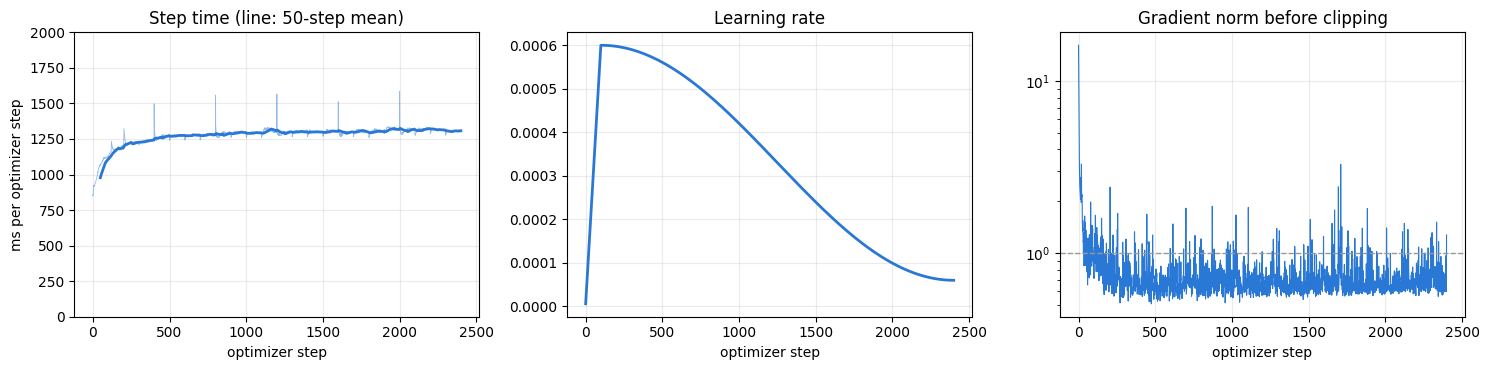

median step time: steps 1-100 1,072 ms (15,287 tokens/s) | last 100 steps 1,307 ms (12,539 tokens/s)
gradient norm: step 0 16.10 | max after warmup 3.28 at step 1709 | clipped at 198 of 2,400 steps, 128 after warmup


In [13]:
steps = np.arange(len(train_hist))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(steps, step_ms, color=BLUE, linewidth=0.6, alpha=0.5)
axes[0].plot(steps[49:], np.convolve(step_ms, np.ones(50) / 50, mode='valid'), color=BLUE, linewidth=2)
axes[0].set_title('Step time (line: 50-step mean)')
axes[0].set_ylabel('ms per optimizer step')
axes[0].set_ylim(0, 2000)
axes[1].plot(steps, [r['lr'] for r in train_hist], color=BLUE, linewidth=2)
axes[1].set_title('Learning rate')
axes[2].plot(steps, [r['grad_norm'] for r in train_hist], color=BLUE, linewidth=0.8)
axes[2].axhline(1.0, color=GREY, linestyle='--', linewidth=1)
axes[2].set_title('Gradient norm before clipping')
axes[2].set_yscale('log')
for ax in axes:
    ax.set_xlabel('optimizer step')
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
first_100, last_100 = statistics.median(step_ms[1:101]), statistics.median(step_ms[-100:])
print(f'median step time: steps 1-100 {first_100:,.0f} ms ({16384 / first_100 * 1000:,.0f} tokens/s) | last 100 steps {last_100:,.0f} ms ({16384 / last_100 * 1000:,.0f} tokens/s)')
norms = [r['grad_norm'] for r in train_hist]
print(f"gradient norm: step 0 {norms[0]:.2f} | max after warmup {max(norms[100:]):.2f} at step {100 + int(np.argmax(norms[100:]))} | "
      f"clipped at {sum(n > 1 for n in norms)} of 2,400 steps, {sum(n > 1 for n in norms[100:])} after warmup")

**Reading the run.** The run completed all 2,400 steps: **39,321,600 tokens in 51.0 minutes of training, 12,840 tokens/s on average**, with a peak of 3.9 GiB allocated. This is about 27% below the 17,525 tokens/s of the cool-GPU benchmark for the same shape: the step time rises during the first minutes and then stays near 1.3 s, which is the laptop GPU's sustained speed rather than its burst speed. The median step took 1,072 ms over the first 100 steps and 1,307 ms over the last 100. The 25 evaluations, 7 rounds of samples and 6 checkpoints added about 5 minutes: the run took about 56 minutes from start to end.

The training loss fell from **10.94 at the first step to 4.86 at the last (5.06 averaged over the last 100 steps)**. The learning rate ended at exactly its minimum, \(6\times10^{-5}\). The gradient norm started at 16.1; after warmup it exceeded the clipping limit of 1.0 at 128 of 2,300 steps, with a largest value of 3.28 (step 1,709), so clipping acted on occasional large gradients rather than on every step as in Week 11's short run.

# 2. Eğitim sırasında belli aralıklarla doğrulama loss'unu ölç ve modelden kısa bir metin ürettir. Train ve val loss'u aynı grafikte çiz.

## 5. Training and Validation Loss

### Three Losses, Measured Differently

| Name | Measured on | When | Procedure |
|---|---|---|---|
| **per-step training loss** | the 8 microbatches of the current step (16,384 tokens, different at every step) | every step, before the update | training mode, the mean of the 8 microbatch losses; noisy |
| **train-eval loss** | the first 100 batches of 8 × 256 tokens of the training split (204,800 tokens) | every 100 steps | `model.eval()`, `torch.no_grad()`, BF16 autocast, mean over the 100 batches; always the same batches |
| **validation loss** | the first 100 batches of 8 × 256 tokens of the validation split (204,800 tokens) | every 100 steps | identical to train-eval |

The per-step loss and the validation loss are **not comparable** with each other: one is a single noisy batch seen during the update, the other a fixed 204,800-token average. The **train-eval and validation losses are computed by the same function** with the same batch shape and number of batches, and only the split differs, so their difference is a proper generalization gap. One detail matters for reading it: the train-eval batches are the first 204,800 tokens of the training stream, which the model trained on during steps 0–12 and never again. So this gap compares **text seen once, about 2,400 steps ago** with **text never seen**, and not text being memorized.

GPT-2 has no dropout, so `eval()` changes nothing in the computation here; I still switch modes as a matter of correctness. Both modes return to training afterwards.

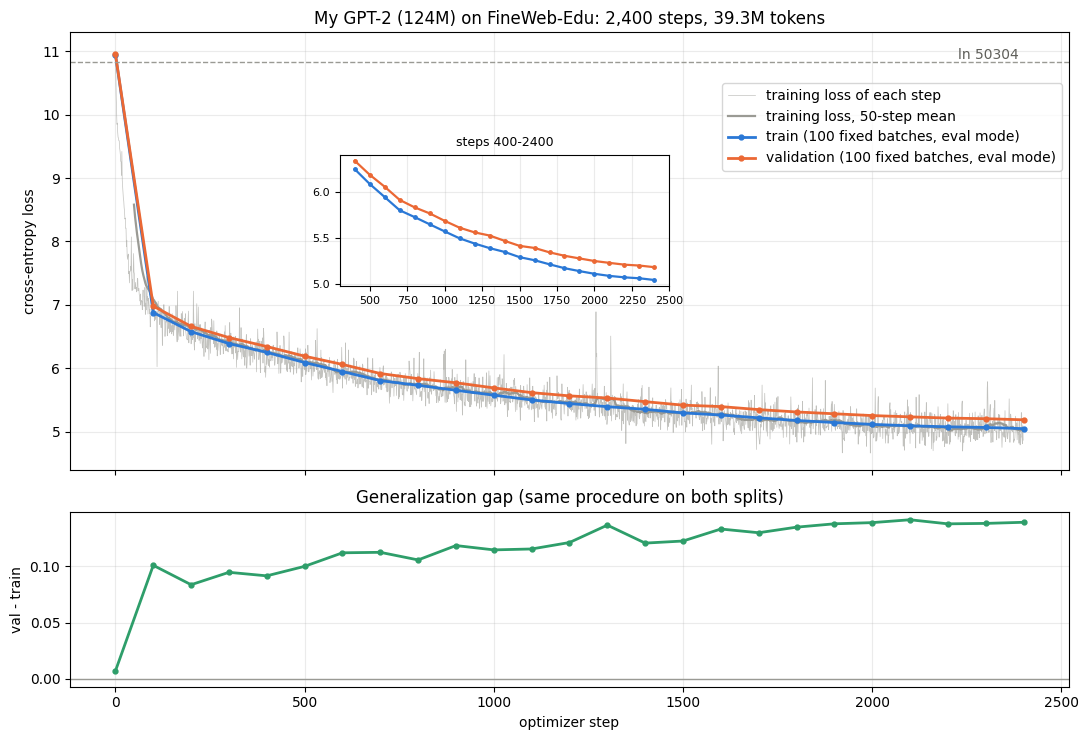

| Step | Tokens | LR | Training loss, last 100 steps | Train-eval loss | Validation loss | Gap |
|---:|---:|---:|---:|---:|---:|---:|
| 0 | 0 | 6.00e-06 | — | 10.948 | 10.955 | +0.007 |
| 400 | 6,553,600 | 5.78e-04 | 6.305 | 6.250 | 6.342 | +0.092 |
| 800 | 13,107,200 | 4.86e-04 | 5.758 | 5.730 | 5.835 | +0.106 |
| 1,200 | 19,660,800 | 3.48e-04 | 5.470 | 5.443 | 5.564 | +0.121 |
| 1,600 | 26,214,400 | 2.06e-04 | 5.292 | 5.262 | 5.395 | +0.133 |
| 2,000 | 32,768,000 | 9.93e-05 | 5.095 | 5.114 | 5.253 | +0.139 |
| 2,400 | 39,321,600 | 6.00e-05 | 5.065 | 5.047 | 5.186 | +0.139 |

In [14]:
evals = history['eval']
ev_steps = [r['step'] for r in evals]
train_losses = np.array([r['loss'] for r in train_hist])
fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={'height_ratios': [3, 1.2]})
ax = axes[0]
ax.plot(steps, train_losses, color=GREY, linewidth=0.5, alpha=0.6, label='training loss of each step')
ax.plot(steps[49:], np.convolve(train_losses, np.ones(50) / 50, mode='valid'), color=GREY, linewidth=1.6, label='training loss, 50-step mean')
ax.plot(ev_steps, [r['train_eval_loss'] for r in evals], color=BLUE, linewidth=2, marker='o', markersize=3.5, label='train (100 fixed batches, eval mode)')
ax.plot(ev_steps, [r['val_loss'] for r in evals], color=ORANGE, linewidth=2, marker='o', markersize=3.5, label='validation (100 fixed batches, eval mode)')
ax.axhline(math.log(50304), color=GREY, linestyle='--', linewidth=1)
ax.text(2400, math.log(50304), 'ln 50304 ', ha='right', va='bottom', color='#5f5f5a')
ax.set_ylabel('cross-entropy loss')
ax.set_title('My GPT-2 (124M) on FineWeb-Edu: 2,400 steps, 39.3M tokens')
ax.set_ylim(4.4, 11.3)
ax.grid(alpha=0.25)
ax.legend(loc='upper right', bbox_to_anchor=(1.0, 0.9))
inset = ax.inset_axes([0.27, 0.42, 0.33, 0.3])
for key, color in [('train_eval_loss', BLUE), ('val_loss', ORANGE)]:
    inset.plot(ev_steps[4:], [r[key] for r in evals[4:]], color=color, linewidth=1.6, marker='o', markersize=2.5)
inset.set_title('steps 400-2400', fontsize=9)
inset.tick_params(labelsize=8)
inset.grid(alpha=0.25)
axes[1].plot(ev_steps, [r['val_loss'] - r['train_eval_loss'] for r in evals], color=GREEN, linewidth=2, marker='o', markersize=3.5)
axes[1].axhline(0, color=GREY, linewidth=1)
axes[1].set_ylabel('val - train')
axes[1].set_xlabel('optimizer step')
axes[1].set_title('Generalization gap (same procedure on both splits)')
axes[1].grid(alpha=0.25)
plt.tight_layout()
fig.savefig(run_dir / 'loss_curves.png', dpi=120)
plt.show()

rows = ['| Step | Tokens | LR | Training loss, last 100 steps | Train-eval loss | Validation loss | Gap |', '|---:|---:|---:|---:|---:|---:|---:|']
for r in evals:
    if r['step'] % 400 == 0:
        lr = train_hist[min(r['step'], 2399)]['lr']
        recent = '—' if r['train_loss_recent_mean'] is None else f"{r['train_loss_recent_mean']:.3f}"
        rows.append(f"| {r['step']:,} | {r['tokens_processed']:,} | {lr:.2e} | {recent} | {r['train_eval_loss']:.3f} | {r['val_loss']:.3f} | {r['val_loss'] - r['train_eval_loss']:+.3f} |")
display(Markdown('\n'.join(rows)))

### Validation Loss of OpenAI's GPT-2 on My Split

The same 100 validation batches can also be given to OpenAI's GPT-2. Its vocabulary has 50,257 entries, so for this comparison **both models' logits are restricted to the 50,257 real tokens** (for my model this renormalizes away the 47 padding classes). Both use BF16 autocast and a context of 256 tokens, as in my evaluation during training. Computed once (about 1 minute) and cached.

In [15]:
@torch.no_grad()
def val_loss_real_vocab(model, n_batches=100, B=8, T=256):
    # the validation loss of train.py, with the softmax over the 50,257 real tokens only
    loader = ShardedDataLoader(data_dir, 'val', B, T)
    model.eval()
    total = 0.0
    for _ in range(n_batches):
        x, y = loader.next_batch()
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
            logits, _ = model(x)
        logits = logits[..., :GPT2_VOCAB_SIZE].float()
        total += F.cross_entropy(logits.reshape(-1, GPT2_VOCAB_SIZE), y.reshape(-1)).item()
    return total / n_batches

def load_checkpoint_model(step):
    ckpt = torch.load(ckpt_dir / f'ckpt_step_{step:06d}.pt', map_location='cpu', weights_only=False)
    model = GPT(GPTConfig(**ckpt['model_config']))
    model.load_state_dict(ckpt['model'])
    return model.to(device).eval()

cache = results_dir / 'val_loss_comparison.json'
if not cache.exists():
    set_tf32(True)
    mine = load_checkpoint_model(2400)
    result = dict(batches=100, batch_shape=[8, 256], tokens=100 * 8 * 256, precision='bf16 autocast, tf32',
                  mine_full_vocab=estimate_loss(mine, data_dir, 'val', 8, 256, 100, device), mine_real_vocab=val_loss_real_vocab(mine))
    del mine
    gpt2 = from_pretrained('gpt2').to(device).eval()
    result['gpt2_real_vocab'] = val_loss_real_vocab(gpt2)
    del gpt2
    torch.cuda.empty_cache()
    set_tf32(False)
    cache.write_text(json.dumps(result, indent=2), encoding='utf-8')
val_cmp = json.loads(cache.read_text(encoding='utf-8'))
print(f"my model, step 2400:  {val_cmp['mine_full_vocab']:.4f} over 50,304 classes (as in training) | {val_cmp['mine_real_vocab']:.4f} over the 50,257 real tokens")
print(f"OpenAI GPT-2 (124M):  {val_cmp['gpt2_real_vocab']:.4f} over the 50,257 real tokens")
print(f"difference: {val_cmp['mine_real_vocab'] - val_cmp['gpt2_real_vocab']:.4f} nats per token | perplexity {math.exp(val_cmp['mine_real_vocab']):,.0f} vs {math.exp(val_cmp['gpt2_real_vocab']):,.0f}")
assert abs(val_cmp['mine_full_vocab'] - history['eval'][-1]['val_loss']) < 1e-3 # the same number as at the end of training

my model, step 2400:  5.1859 over 50,304 classes (as in training) | 5.1860 over the 50,257 real tokens
OpenAI GPT-2 (124M):  3.6361 over the 50,257 real tokens
difference: 1.5498 nats per token | perplexity 179 vs 38


### Reading the Loss Curves

**Start.** Before training, the validation loss is 10.955 and the train-eval loss 10.948, both close to \(\ln 50304 = 10.83\) for a uniform guess over the output classes, as expected from random weights.

**Training.** Most of the decrease happens early: the validation loss falls by 4.61 in the first 400 steps (6.6M tokens), from 10.96 to 6.34. Later it keeps falling, but each 400 steps gain less: 0.14 between steps 1,600 and 2,000, and 0.07 between 2,000 and 2,400, when the learning rate is near its minimum. The final values are **5.047 for train-eval and 5.186 for validation**; the per-step training loss averages 5.065 over the last 100 steps, consistent with the train-eval value although it is measured differently. The curve is still going down at the end, so the model is limited by its training budget, not by its capacity.

**Generalization gap.** The gap between the two fixed sets, measured with the same procedure, grows from 0.007 at the start to 0.139 at step 2,000 and stays at 0.139 at step 2,400. The model is better on the training batches than on unseen documents, but the validation loss decreased at every evaluation, so **no clear signs of overfitting were observed during this training run**; each training token was used at most once, and a longer run or repeated epochs could behave differently. The train-eval batches were seen once, at steps 0–12, so the gap partly reflects that one exposure. Part of it may also be that the two fixed sets contain different documents; with one run, I cannot separate the two effects.

**OpenAI's GPT-2 on my validation split** reaches **3.636**, against **5.186** for my model, a difference of 1.55 nats per token (perplexity 38 against 179). GPT-2 has never seen FineWeb-Edu, and it still predicts this text far better than my model trained on 39M tokens of it. Restricting my model to the 50,257 real tokens changes its loss from 5.1859 to 5.1860: after training, the 47 padding classes hold almost no probability, as Week 11 predicted.

## 6. Text Generation Across Checkpoints

### Settings

At steps 0 (the random model), 400, 800, …, 2,400, `train.py` generated one continuation per prompt with **the same settings at every stage**: the prompts `The history of science`, `In the future, technology`, `Once upon a time`; GPT-2 tokenizer; `temperature = 1.0`; `top_k = 50`; **48 new tokens**; and a separate `torch.Generator` seeded with `1337 + prompt index` at every stage, so that the random draws are reproducible and do not touch the training's random state. Generation runs in eval mode under BF16 autocast and samples only among the 50,257 real tokens.

In [16]:
def show(text, width=110):
    return textwrap.fill(text.replace('\n', ' ⏎ '), width=width, subsequent_indent='      ')

by_step = {g['step']: {s['prompt']: s['text'] for s in g['samples']} for g in history['samples']}
for prompt in PROMPTS:
    print(f'=== {prompt!r}')
    for step, samples in by_step.items():
        print(f'{step:>5}: ' + show(samples[prompt]))
    print()

=== 'The history of science'
    0: The history of science Werewolfordesagically managed Crafting Thomson Strip removed Sad snowy takeover reveal
      Hilbert reveal pace•• flaw BlasioilianLV airstrike Parents occasionalAREervesARE surge were Parking
      faces̶••mates counter continental decimal136 sandwich POL368IV Patriotillin Journal definitely 133 ibn
      astonished
  400: The history of science, and their families of the children on many of a new day before they don’t start with
      you, but we don’t work, and ’t mean if I remember if sure, so you to think, but
  800: The history of science. ⏎ This new data is used according to the information on the project that makes the
      research strategy (A third-old) that is the first major role of human life. ⏎ The research program
      includes reports on an opportunity to make new activity
 1200: The history of science and the human history and the universe becomes from the earth. ⏎ Many are known as in
      the Old Age of a 

### Measuring the Change

Three samples per stage are too few to judge. For a measurement, I generated **8 continuations for each of the 3 prompts** (24 per model, the same settings, generator seed 1337 per prompt) from the random model, from every checkpoint, and from OpenAI's GPT-2. On the generated part only:

- **Known-word rate:** the share of generated words (runs of letters) that occur at least 3 times in the validation split's text. Random tokens produce word fragments and rare names; English text uses common words.
- **Distinct bigrams:** distinct token pairs / all token pairs. Low values mean the sample repeats itself.
- **Repeated trigrams:** the share of token triples that already occurred earlier in the same sample.
- **NLL under OpenAI's GPT-2:** the mean loss that OpenAI's GPT-2 assigns to the generated tokens given the prompt. Lower means text that GPT-2 finds more probable; it is an external but imperfect judge of fluency.

Computed once (about 2 minutes) and cached.

In [17]:
cache = results_dir / 'generation_metrics.json'
if not cache.exists():
    set_tf32(False)
    val_text = enc.decode(ShardedDataLoader(data_dir, 'val', 1, 8).read(0, 1_000_000).tolist())
    word_counts = Counter(w.lower() for w in re.findall(r'[A-Za-z]+', val_text))
    known = {w for w, c in word_counts.items() if c >= 3}
    judge = from_pretrained('gpt2').to(device).eval()

    @torch.no_grad()
    def judge_nll(ids, n_prompt):
        logits, _ = judge(ids.unsqueeze(0))
        return F.cross_entropy(logits[0, n_prompt - 1:-1].float(), ids[n_prompt:]).item()

    def sample_stats(model):
        out = []
        for i, prompt in enumerate(PROMPTS):
            ids = torch.tensor([enc.encode(prompt)], device=device).repeat(8, 1)
            gen = generate(model, ids, 48, temperature=1.0, top_k=50, generator=torch.Generator(device=device).manual_seed(seed + i))
            for row in gen:
                cont = row[ids.size(1):].tolist()
                words = re.findall(r'[A-Za-z]+', enc.decode(cont))
                bigrams, trigrams = list(zip(cont, cont[1:])), list(zip(cont, cont[1:], cont[2:]))
                out.append(dict(prompt=prompt, text=enc.decode(row.tolist()),
                                known_word_rate=sum(w.lower() in known for w in words) / max(len(words), 1),
                                distinct_bigrams=len(set(bigrams)) / len(bigrams),
                                repeated_trigrams=1 - len(set(trigrams)) / len(trigrams),
                                judge_nll=judge_nll(row, ids.size(1))))
        return out

    metrics = {}
    model = build_model(GPTConfig(), seed, device).eval() # the random initialization of the run
    metrics['0'] = sample_stats(model)
    for step in range(400, 2401, 400):
        model = load_checkpoint_model(step)
        metrics[str(step)] = sample_stats(model)
    metrics['gpt2'] = sample_stats(judge)
    del model, judge
    torch.cuda.empty_cache()
    cache.write_text(json.dumps(metrics, indent=2), encoding='utf-8')
gen_metrics = json.loads(cache.read_text(encoding='utf-8'))

keys = ['known_word_rate', 'distinct_bigrams', 'repeated_trigrams', 'judge_nll']
rows = ['| Model | Training tokens | Known-word rate | Distinct bigrams | Repeated trigrams | NLL under OpenAI GPT-2 |', '|---|---:|---:|---:|---:|---:|']
for name, samples in gen_metrics.items():
    label = 'OpenAI GPT-2' if name == 'gpt2' else f'mine, step {int(name):,}'
    tokens = '—' if name == 'gpt2' else f'{int(name) * 16384 / 1e6:.1f}M'
    vals = [statistics.mean(s[k] for s in samples) for k in keys]
    rows.append(f'| {label} | {tokens} | {vals[0]:.1%} | {vals[1]:.3f} | {vals[2]:.1%} | {vals[3]:.2f} |')
display(Markdown('\n'.join(rows)))
print('24 samples per model (3 prompts x 8). Two samples per stage for the first prompt:')
for name in ['0', '1200', '2400', 'gpt2']:
    for s in [x for x in gen_metrics[name] if x['prompt'] == PROMPTS[0]][:2]:
        print(f'{name:>5}: ' + show(s['text']))

| Model | Training tokens | Known-word rate | Distinct bigrams | Repeated trigrams | NLL under OpenAI GPT-2 |
|---|---:|---:|---:|---:|---:|
| mine, step 0 | 0.0M | 38.3% | 1.000 | 0.0% | 13.27 |
| mine, step 400 | 6.6M | 99.9% | 0.957 | 0.7% | 5.14 |
| mine, step 800 | 13.1M | 98.9% | 0.949 | 0.9% | 4.92 |
| mine, step 1,200 | 19.7M | 99.6% | 0.949 | 0.8% | 4.57 |
| mine, step 1,600 | 26.2M | 99.7% | 0.968 | 0.5% | 4.36 |
| mine, step 2,000 | 32.8M | 99.9% | 0.962 | 0.5% | 4.24 |
| mine, step 2,400 | 39.3M | 99.4% | 0.972 | 0.2% | 4.26 |
| OpenAI GPT-2 | — | 98.4% | 0.968 | 0.6% | 2.71 |

24 samples per model (3 prompts x 8). Two samples per stage for the first prompt:
    0: The history of science WerewolfザELL thousandonson marking Parade tabl ride SE upgr fightCHRtier
      replacementsordsaur Rudloo Kats戦 sees Denmarkloo elsewhere–– yieldedIn unimaginable Property
      Property戦Felprot tablCHR problezn̶ dangers calling Lindboy elsewhere Gu ✔ Recent declare
    0: The history of science DOCords embrace hairc Ah warp 1861rities zo Architecture jetsspread PRESCHR368 Phone i
      preemptane �________________________________________________________________ Rocket649 cor Reve area Sit
      sensorycomp innocuous Keynes articulated upscale buddies capitalist cafe Flint belonging legacy
      caucusesBrexit segregated DCiculty� Mickey scenicSword
 1200: The history of science and the human history and the universe becomes from the earth. ⏎ Many are known as in
      the Old Age of a human, is a very small amount of the surface. ⏎ How are the world or then the following
   

### How the Generated Text Changes

**Step 0, random weights.** A sequence of unrelated tokens from the whole vocabulary: word pieces, names, symbols, and non-Latin characters. Only 38% of the generated words are common words, and OpenAI's GPT-2 assigns these tokens a loss of 13.3 nats, worse than a uniform guess.

**Step 400 (6.6M tokens).** Almost every word is now a common English word (99.9%), with function words and punctuation in plausible places: *"The second type of new systems are in the United system."* Phrases are locally grammatical, but sentences break after a few words, and nothing connects to the prompt. The loss under GPT-2 falls to 5.14.

**Steps 800–1,200 (13–20M tokens).** Sentences have a subject and a verb more often, the text has paragraphs (line breaks), and some words follow the prompt's topic: *"The history of science and the human history and the universe..."*, *"the Middle Ages of the region of Europe"*. The content still does not make sense.

**Steps 1,600–2,400 (26–39M tokens).** Longer grammatical stretches in the register of FineWeb-Edu: universities, institutes, research programs, lists of references (*"- New York University Medical Journal"*). Some continuations start well, for example *"In the future, technology is an alternative or effective and cost-efficient products and are widely implemented."*, but the topic drifts within one or two sentences. The loss under GPT-2 goes from 4.57 (step 1,200) to 4.36, 4.24 and 4.26: the last 400 steps did not make the samples measurably more GPT-2-like.

**What did not change.** Repetition was never the problem at `temperature = 1.0` with top-k: distinct bigrams stay between 0.95 and 0.97 and repeated trigrams below 1% at every stage, as for OpenAI's GPT-2. The known-word rate is saturated from step 400 on, so it cannot separate the later checkpoints. The improvement after step 400 is in **grammar over longer spans and topical consistency**, not in vocabulary.

**Compared with OpenAI's GPT-2.** Its samples are fluent, grammatical sentences that stay connected to the prompt, although they can drift as well (one sample moves from the history of science to artificial intelligence and censorship). Its loss of 2.71 under itself is not a fair number, because a model always finds its own samples likely; it only shows the direction. My model does not produce coherent English, and I would not call it pretrained: it has learned English words, local syntax and the style of educational web pages, but not consistent meaning.

# 4. HellaSwag'i önce kendi modelinde, sonra OpenAI'ın GPT-2 ağırlıklarında koş. Rastgele tahmin yüzde 25 doğru bulur. Senin modelin ne kadar buluyor, OpenAI'ın modelinden ne kadar uzakta? Aradaki farkın nereden geldiğini kendi cümlelerinle yaz.

## 7. HellaSwag: The Evaluation Method

### The Data

Each HellaSwag example is the beginning of a description of an everyday situation (from ActivityNet video captions or WikiHow articles) and **four endings**: the real one and three wrong ones. The wrong endings were **generated by a language model and then filtered adversarially**: endings that the discriminator models of 2019 could easily reject were replaced, so that the remaining ones look plausible to models while being easy for humans (over 95% human accuracy). I use the **full validation split, 10,042 examples**, for both models.

**Source.** The official GitHub repository (`rowanz/hellaswag`), which Karpathy's script downloads from, has been blocked by a DMCA notice since 2026-09-14 (the claim concerns the WikiHow text). I read the validation split from the dataset author's own Hugging Face repository, **`Rowan/hellaswag`, pinned to revision `218ec52e09a7`**, which contains the same 10,042 examples with the same fields.

### Scoring

Let \(c\) be the context tokens and \(e^{(j)}=(e^{(j)}_1,\dots,e^{(j)}_{n_j})\) the tokens of ending \(j\), encoded as `" " + ending`, because GPT-2 tokens carry their leading space. The model reads the row \(c\,e^{(j)}\), and only the ending tokens are scored:

\[
S_j=-\sum_{i=1}^{n_j}\log p_\theta\!\left(e^{(j)}_i \,\middle|\, c,\ e^{(j)}_{<i}\right),\qquad A_j=\frac{S_j}{n_j}
\]

\[
\hat y_{\text{acc}}=\arg\min_j S_j,\qquad \hat y_{\text{acc\_norm}}=\arg\min_j A_j
\]

- **Alignment.** The logits at position \(t\) predict token \(t+1\). After shifting, the mask is shifted with the targets, so the **first ending token is scored by the logits of the last context token**, and no context token is scored.
- **Padding.** The four rows have different lengths and are padded with zeros at the end. With causal attention, a token never sees anything to its right, so padding cannot change the scores of the real tokens, and padded positions are masked out.
- **The label** is read only after the four losses are computed; the model never receives it.
- **Normalization.** \(A_j\) divides by the number of **tokens**. This is the build-nanogpt definition of `acc_norm`. EleutherAI's evaluation harness divides by the number of **characters**, so its published `acc_norm` values are not the same metric.
- **Identical conditions.** Both models are instances of my `GPT` class (OpenAI's weights are loaded into it as in Week 10), run in **float32 without TF32**, see the same 10,042 examples, and the logits of both are restricted to the 50,257 real tokens. The longest row is 166 tokens, shorter than my training context of 256, so **no truncation** happens for either model.

In [18]:
examples, source = hs.load_hellaswag_val()
print(f"{len(examples):,} validation examples | {source['repo']} @ {source['revision'][:12]} | file {source['file']}")
lengths = [hs.render_example(e, enc, 1024)[0].size(1) for e in examples]
print(f'row length (context + longest ending): median {int(np.median(lengths))}, max {max(lengths)} tokens -> truncated for a context of 256: {sum(l > 256 for l in lengths)}')

e = examples[0]
tokens, mask, truncated = hs.render_example(e, enc, 1024)
n_ctx = len(enc.encode(e['ctx']))
print(f"\ncontext ({n_ctx} tokens): {e['ctx']!r}")
for j, ending in enumerate(e['endings']):
    print(f'  ending {j} ({int(mask[j].sum())} tokens): {ending!r}')
print('\nrow 0 tokens:', tokens[0].tolist())
print('row 0 mask:  ', mask[0].tolist())

10,042 validation examples | Rowan/hellaswag @ 218ec52e09a7 | file data/validation-00000-of-00001.parquet


row length (context + longest ending): median 105, max 166 tokens -> truncated for a context of 256: 0

context (9 tokens): 'A man is sitting on a roof. he'
  ending 0 (11 tokens): 'is using wrap to wrap a pair of skis.'
  ending 1 (6 tokens): 'is ripping level tiles off.'
  ending 2 (8 tokens): "is holding a rubik's cube."
  ending 3 (9 tokens): 'starts pulling up roofing on a roof.'

row 0 tokens: [32, 582, 318, 5586, 319, 257, 9753, 13, 339, 318, 1262, 14441, 284, 14441, 257, 5166, 286, 1341, 271, 13]
row 0 mask:   [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [19]:
log = (results_dir / 'sanity_checks_log.txt').read_text(encoding='utf-8')
print(log[log.index('== HellaSwag'):log.index('HellaSwag checks passed')].strip())

== HellaSwag scoring ==
10042 validation examples from Rowan/hellaswag @ 218ec52e09
row length (context + longest ending): median 105, 99th pct 136, max 166 tokens; > 256: 0, > 512: 0
example 0: 9 context tokens | sum losses [43.422, 34.639, 23.589, 36.631] | label 3
first-token alignment, padding invariance, ending permutation, and truncation checks passed
   10/20 | acc 0.5000 | acc_norm 0.3000 | 0 s
   20/20 | acc 0.3500 | acc_norm 0.2000 | 1 s
gpt2: 20 examples | acc 7/20 = 0.3500 | acc_norm 4/20 = 0.2000 | 1 s
   10/20 | acc 0.4000 | acc_norm 0.2000 | 0 s
   20/20 | acc 0.3000 | acc_norm 0.2000 | 1 s
random-init: 20 examples | acc 6/20 = 0.3000 | acc_norm 4/20 = 0.2000 | 1 s
33 ms per example in float32 -> about 0.6 min for 1,000 examples, 5.5 min for all 10,042


`sanity_checks.check_hellaswag` verifies, with OpenAI's GPT-2 on example 0: the summed loss equals the log-probabilities of the ending tokens taken by hand from the position before each token; scoring each ending alone without padding gives the same losses; permuting the four endings permutes the losses in the same way; truncation keeps the endings whole. It then runs 20 examples on GPT-2 and on a randomly initialized model. Those 20-example accuracies are only a smoke test.

The full evaluations:

    python week-12/evaluate_hellaswag.py --model mine --checkpoint week-12/checkpoints/main/ckpt_step_002400.pt --n_examples 10042
    python week-12/evaluate_hellaswag.py --model gpt2 --n_examples 10042
    python week-12/evaluate_hellaswag.py --compare week-12/results/hellaswag_mine.json week-12/results/hellaswag_gpt2.json

## 8. My Model vs OpenAI's GPT-2

In [20]:
res = {name: json.loads((results_dir / f'hellaswag_{name}.json').read_text(encoding='utf-8')) for name in ['mine', 'gpt2']}
cmp = json.loads((results_dir / 'hellaswag_comparison.json').read_text(encoding='utf-8'))
mine, gpt2 = res['mine'], res['gpt2']
assert mine['indices'] == gpt2['indices'] == list(range(10042)) and mine['complete'] and gpt2['complete']
assert mine['autocast'] is gpt2['autocast'] is False and mine['max_context'] == gpt2['max_context'] and mine['truncated_examples'] == gpt2['truncated_examples'] == 0
# recount from the per-example records instead of trusting the stored totals
for r in res.values():
    assert r['correct'] == sum(x['pred_sum'] == x['label'] for x in r['records'])
    assert r['correct_norm'] == sum(x['pred_norm'] == x['label'] for x in r['records'])

def ci(k, n):
    lo, hi = hs.wilson_interval(k, n)
    return f'{100 * lo:.1f} – {100 * hi:.1f}'

n = mine['n_examples']
rows = ['| Metric | My trained GPT-2 | OpenAI GPT-2 |', '|---|---:|---:|',
        '| Parameters | 124,475,904 (vocab padded to 50,304) | 124,439,808 |',
        '| Training corpus | FineWeb-Edu `sample-10BT`, 40M-token subset | WebText (OpenAI, pretrained reference) |',
        f"| FineWeb-Edu tokens processed | {summary['tokens_processed']:,} (0.98 epochs) | not applicable |",
        f"| Validation loss on my split (50,257 real tokens) | {val_cmp['mine_real_vocab']:.3f} | {val_cmp['gpt2_real_vocab']:.3f} |",
        f'| HellaSwag examples | {n:,} | {n:,} |',
        f"| HellaSwag accuracy (summed loss) | {mine['correct']:,} = **{100 * mine['accuracy']:.2f}%** (95% CI {ci(mine['correct'], n)}) | {gpt2['correct']:,} = **{100 * gpt2['accuracy']:.2f}%** (95% CI {ci(gpt2['correct'], n)}) |",
        f"| HellaSwag normalized accuracy (mean loss per token) | {mine['correct_norm']:,} = **{100 * mine['accuracy_norm']:.2f}%** (95% CI {ci(mine['correct_norm'], n)}) | {gpt2['correct_norm']:,} = **{100 * gpt2['accuracy_norm']:.2f}%** (95% CI {ci(gpt2['correct_norm'], n)}) |",
        f"| Random-chance baseline | 25.00% | 25.00% |",
        f"| Above chance (acc / acc_norm, pp) | {100 * mine['accuracy'] - 25:+.2f} / {100 * mine['accuracy_norm'] - 25:+.2f} | {100 * gpt2['accuracy'] - 25:+.2f} / {100 * gpt2['accuracy_norm'] - 25:+.2f} |"]
display(Markdown('\n'.join(rows)))
for key, label in [('accuracy', 'acc'), ('accuracy_norm', 'acc_norm')]:
    c = cmp[key]
    print(f"{label:8s}: OpenAI - mine = {c['difference_pp']:+.2f} pp | only mine correct {c['only_first_correct']:,}, only OpenAI correct {c['only_second_correct']:,} | "
          f"McNemar chi2 = {c['mcnemar_chi2']:.1f} (1 d.o.f.; 3.84 is p = 0.05)")

| Metric | My trained GPT-2 | OpenAI GPT-2 |
|---|---:|---:|
| Parameters | 124,475,904 (vocab padded to 50,304) | 124,439,808 |
| Training corpus | FineWeb-Edu `sample-10BT`, 40M-token subset | WebText (OpenAI, pretrained reference) |
| FineWeb-Edu tokens processed | 39,321,600 (0.98 epochs) | not applicable |
| Validation loss on my split (50,257 real tokens) | 5.186 | 3.636 |
| HellaSwag examples | 10,042 | 10,042 |
| HellaSwag accuracy (summed loss) | 2,616 = **26.05%** (95% CI 25.2 – 26.9) | 2,870 = **28.58%** (95% CI 27.7 – 29.5) |
| HellaSwag normalized accuracy (mean loss per token) | 2,408 = **23.98%** (95% CI 23.2 – 24.8) | 2,967 = **29.55%** (95% CI 28.7 – 30.4) |
| Random-chance baseline | 25.00% | 25.00% |
| Above chance (acc / acc_norm, pp) | +1.05 / -1.02 | +3.58 / +4.55 |

acc     : OpenAI - mine = +2.53 pp | only mine correct 562, only OpenAI correct 816 | McNemar chi2 = 46.5 (1 d.o.f.; 3.84 is p = 0.05)
acc_norm: OpenAI - mine = +5.57 pp | only mine correct 1,053, only OpenAI correct 1,612 | McNemar chi2 = 116.8 (1 d.o.f.; 3.84 is p = 0.05)


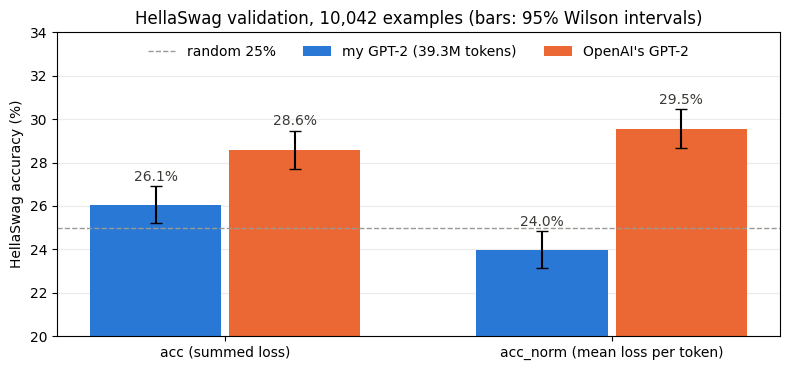

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(2)
for k, (name, color) in enumerate([('mine', BLUE), ('gpt2', ORANGE)]):
    vals = [100 * res[name]['accuracy'], 100 * res[name]['accuracy_norm']]
    errs = [[v - 100 * hs.wilson_interval(c, n)[0] for v, c in zip(vals, [res[name]['correct'], res[name]['correct_norm']])],
            [100 * hs.wilson_interval(c, n)[1] - v for v, c in zip(vals, [res[name]['correct'], res[name]['correct_norm']])]]
    ax.bar(x + (k - 0.5) * 0.36, vals, width=0.34, color=color, yerr=errs, capsize=4,
           label='my GPT-2 (39.3M tokens)' if name == 'mine' else "OpenAI's GPT-2")
    for xi, v, up in zip(x + (k - 0.5) * 0.36, vals, errs[1]):
        ax.text(xi, v + up + 0.25, f'{v:.1f}%', ha='center', color='#3a3a36')
ax.axhline(25, color=GREY, linestyle='--', linewidth=1, label='random 25%')
ax.set_xticks(x, ['acc (summed loss)', 'acc_norm (mean loss per token)'])
ax.set_ylim(20, 34)
ax.set_ylabel('HellaSwag accuracy (%)')
ax.set_title('HellaSwag validation, 10,042 examples (bars: 95% Wilson intervals)')
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
ax.legend(loc='upper center', ncol=3, frameon=False)
plt.tight_layout()
plt.show()

### Where Does Each Model Get Its Answers Right?

Two diagnostics from the per-example losses that were saved: accuracy by source and split type, and the role of ending **length**, which differs between endings and affects the summed score directly.

In [22]:
labels = np.array([e['label'] for e in examples])
end_len = np.array([[len(enc.encode(' ' + x)) for x in e['endings']] for e in examples])
idx = np.arange(n)
recs = {name: sorted(res[name]['records'], key=lambda r: r['index']) for name in res}
pred = {name: {k: np.array([r[k] for r in recs[name]]) for k in ['pred_sum', 'pred_norm']} for name in res}
avg = {name: np.array([r['avg_loss'] for r in recs[name]]) for name in res}

groups = [('all', np.ones(n, bool)),
          ('ActivityNet', np.array([e['source_id'].startswith('activitynet') for e in examples])),
          ('WikiHow', np.array([e['source_id'].startswith('wikihow') for e in examples])),
          ('in-domain', np.array([e['split_type'] == 'indomain' for e in examples])),
          ('zero-shot', np.array([e['split_type'] == 'zeroshot' for e in examples]))]
rows = ['| Subset | Examples | Mine acc | Mine acc_norm | OpenAI acc | OpenAI acc_norm |', '|---|---:|---:|---:|---:|---:|']
for g, m in groups:
    rows.append(f"| {g} | {m.sum():,} | " + ' | '.join(f"{100 * (pred[name][k][m] == labels[m]).mean():.1f}%" for name in ['mine', 'gpt2'] for k in ['pred_sum', 'pred_norm']) + ' |')
display(Markdown('\n'.join(rows)))

print(f'length baselines without any model: shortest ending {(end_len.argmin(1) == labels).mean():.2%}, longest {(end_len.argmax(1) == labels).mean():.2%}; '
      f'mean length correct {end_len[idx, labels].mean():.1f} vs wrong {(end_len.sum(1) - end_len[idx, labels]).mean() / 3:.1f} tokens')
for name, label in [('mine', 'mine  '), ('gpt2', 'OpenAI')]:
    correct_avg = avg[name][idx, labels].mean()
    wrong_avg = (avg[name].sum(1) - avg[name][idx, labels]).mean() / 3
    print(f"{label}: summed loss picks the shortest ending in {(pred[name]['pred_sum'] == end_len.argmin(1)).mean():.1%} of examples | "
          f"mean loss per token: correct endings {correct_avg:.3f}, wrong endings {wrong_avg:.3f} (difference {wrong_avg - correct_avg:+.3f})")
print('acc_norm predictions per answer slot (mine):', sorted(Counter(pred['mine']['pred_norm'].tolist()).items()), '| labels:', sorted(Counter(labels.tolist()).items()))

| Subset | Examples | Mine acc | Mine acc_norm | OpenAI acc | OpenAI acc_norm |
|---|---:|---:|---:|---:|---:|
| all | 10,042 | 26.1% | 24.0% | 28.6% | 29.5% |
| ActivityNet | 3,243 | 30.3% | 26.8% | 34.0% | 34.8% |
| WikiHow | 6,799 | 24.0% | 22.7% | 26.0% | 27.1% |
| in-domain | 5,001 | 26.0% | 24.3% | 28.9% | 29.5% |
| zero-shot | 5,041 | 26.1% | 23.7% | 28.3% | 29.6% |

length baselines without any model: shortest ending 25.41%, longest 24.27%; mean length correct 31.6 vs wrong 31.5 tokens
mine  : summed loss picks the shortest ending in 75.7% of examples | mean loss per token: correct endings 5.039, wrong endings 5.030 (difference -0.009)
OpenAI: summed loss picks the shortest ending in 68.9% of examples | mean loss per token: correct endings 3.035, wrong endings 3.146 (difference +0.111)
acc_norm predictions per answer slot (mine): [(0, 2550), (1, 2481), (2, 2543), (3, 2468)] | labels: [(0, 2515), (1, 2485), (2, 2584), (3, 2458)]


### Is My Model Better Than No Training?

A model with **random weights** is the natural zero point: it uses the same scoring, so it shows what the scoring rules give by themselves. I evaluated the random initialization of my run (seed 1337) on all 10,042 examples with the same code, and compared all three models with a rule that uses no model at all: **pick the shortest ending**. The comparisons are paired (McNemar, on the examples where exactly one of the two is correct). Computed once (about 5 minutes) and cached.

In [23]:
cache = results_dir / 'hellaswag_random_init.json'
if not (cache.exists() and json.loads(cache.read_text(encoding='utf-8'))['complete']):
    set_tf32(False)
    model = build_model(GPTConfig(), seed, device).eval()
    hs.evaluate(model, examples, list(range(10042)), cache, device, dict(name='random-init', step=0, seed=seed))
    del model
    torch.cuda.empty_cache()
res['random_init'] = json.loads(cache.read_text(encoding='utf-8'))
assert res['random_init']['indices'] == mine['indices'] and res['random_init']['autocast'] is False
recs['random_init'] = sorted(res['random_init']['records'], key=lambda r: r['index'])
pred['random_init'] = {k: np.array([r[k] for r in recs['random_init']]) for k in ['pred_sum', 'pred_norm']}
shortest = end_len.argmin(1)

def mcnemar(correct_a, correct_b):
    a, b = int((correct_a & ~correct_b).sum()), int((correct_b & ~correct_a).sum())
    return a, b, (abs(a - b) - 1) ** 2 / (a + b)

names = {'random_init': 'random init', 'mine': 'mine, step 2400', 'gpt2': 'OpenAI GPT-2'}
rows = ['| Model | acc | acc_norm | Summed loss picks the shortest ending |', '|---|---:|---:|---:|']
for name in names:
    r = res[name]
    rows.append(f"| {names[name]} | {100 * r['accuracy']:.2f}% ({ci(r['correct'], n)}) | {100 * r['accuracy_norm']:.2f}% ({ci(r['correct_norm'], n)}) | {(pred[name]['pred_sum'] == shortest).mean():.1%} |")
rows.append(f"| rule: shortest ending | {100 * (shortest == labels).mean():.2f}% | — | 100% |")
display(Markdown('\n'.join(rows)))

correct = {name: {k: pred[name][k] == labels for k in ['pred_sum', 'pred_norm']} for name in names}
rows = ['| Comparison | Metric | Only first correct | Only second correct | McNemar \\(\\chi^2\\) | Significant at 0.05 (> 3.84) |', '|---|---|---:|---:|---:|---|']
for first, second in [('mine', 'random_init'), ('gpt2', 'random_init'), ('gpt2', 'mine')]:
    for k, label in [('pred_sum', 'acc'), ('pred_norm', 'acc_norm')]:
        a, b, chi2 = mcnemar(correct[first][k], correct[second][k])
        rows.append(f'| {names[first]} vs {names[second]} | {label} | {a:,} | {b:,} | {chi2:.1f} | {"yes" if chi2 > 3.84 else "no"} |')
for name in ['mine', 'gpt2']:
    a, b, chi2 = mcnemar(correct[name]['pred_sum'], shortest == labels)
    rows.append(f'| {names[name]} vs shortest-ending rule | acc | {a:,} | {b:,} | {chi2:.1f} | {"yes" if chi2 > 3.84 else "no"} |')
display(Markdown('\n'.join(rows)))

| Model | acc | acc_norm | Summed loss picks the shortest ending |
|---|---:|---:|---:|
| random init | 25.46% (24.6 – 26.3) | 24.86% (24.0 – 25.7) | 95.5% |
| mine, step 2400 | 26.05% (25.2 – 26.9) | 23.98% (23.2 – 24.8) | 75.7% |
| OpenAI GPT-2 | 28.58% (27.7 – 29.5) | 29.55% (28.7 – 30.4) | 68.9% |
| rule: shortest ending | 25.41% | — | 100% |

| Comparison | Metric | Only first correct | Only second correct | McNemar \(\chi^2\) | Significant at 0.05 (> 3.84) |
|---|---|---:|---:|---:|---|
| mine, step 2400 vs random init | acc | 667 | 608 | 2.6 | no |
| mine, step 2400 vs random init | acc_norm | 1,777 | 1,865 | 2.1 | no |
| OpenAI GPT-2 vs random init | acc | 967 | 654 | 60.1 | yes |
| OpenAI GPT-2 vs random init | acc_norm | 2,187 | 1,716 | 56.6 | yes |
| OpenAI GPT-2 vs mine, step 2400 | acc | 816 | 562 | 46.5 | yes |
| OpenAI GPT-2 vs mine, step 2400 | acc_norm | 1,612 | 1,053 | 116.8 | yes |
| mine, step 2400 vs shortest-ending rule | acc | 665 | 601 | 3.1 | no |
| OpenAI GPT-2 vs shortest-ending rule | acc | 962 | 644 | 62.6 | yes |

### HellaSwag During Training

To see whether the score moves with training, I evaluated the random initialization and the checkpoints at steps 400–2,000 on a fixed sample of **1,000 validation examples** (`select_indices(1000, seed=1337)`), with the same code and float32 settings. For step 2,400 and for OpenAI's GPT-2, the same 1,000 indices are taken from the full evaluations above. With 1,000 examples the 95% interval is about ±2.7 points, so only large changes are visible. Computed once (about 4 minutes) and cached.

| Model | Tokens | acc (1,000 examples) | acc_norm (1,000 examples) |
|---|---:|---:|---:|
| mine, step 0 | 0.0M | 24.4% | 23.8% |
| mine, step 400 | 6.6M | 24.3% | 24.5% |
| mine, step 800 | 13.1M | 24.0% | 25.1% |
| mine, step 1,200 | 19.7M | 24.4% | 25.2% |
| mine, step 1,600 | 26.2M | 23.9% | 24.3% |
| mine, step 2,000 | 32.8M | 24.7% | 23.3% |
| mine, step 2,400 | 39.3M | 24.3% | 24.1% |
| OpenAI GPT-2 | — | 28.3% | 28.0% |

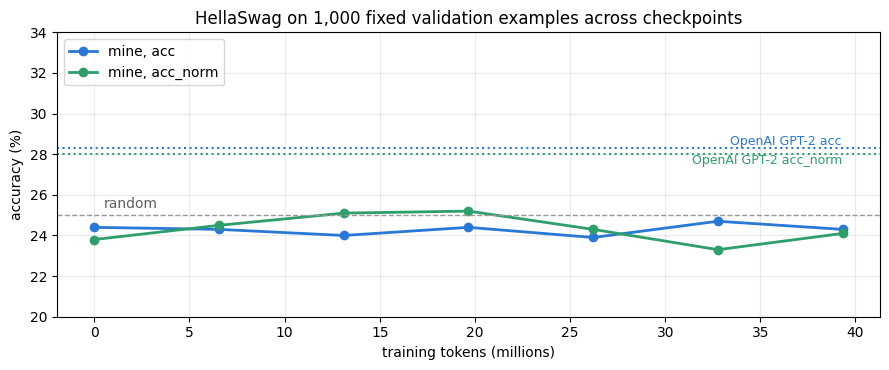

In [24]:
subset = hs.select_indices(1000, seed)
traj_dir = results_dir / 'hellaswag_trajectory'
traj_dir.mkdir(exist_ok=True)
set_tf32(False)
trajectory = {}
for step in [0, 400, 800, 1200, 1600, 2000]:
    out = traj_dir / f'step_{step:06d}.json'
    if not (out.exists() and json.loads(out.read_text(encoding='utf-8'))['complete']):
        model = build_model(GPTConfig(), seed, device).eval() if step == 0 else load_checkpoint_model(step)
        hs.evaluate(model, examples, subset, out, device, dict(name=f'mine-step-{step}', step=step), save_every=1000)
        del model
        torch.cuda.empty_cache()
    r = json.loads(out.read_text(encoding='utf-8'))
    assert r['indices'] == subset
    trajectory[step] = (r['correct'], r['correct_norm'])
in_subset = set(subset)
for name, key in [('mine', 2400), ('gpt2', 'gpt2')]:
    sub = [x for x in res[name]['records'] if x['index'] in in_subset]
    assert len(sub) == 1000
    trajectory[key] = (sum(x['pred_sum'] == x['label'] for x in sub), sum(x['pred_norm'] == x['label'] for x in sub))

rows = ['| Model | Tokens | acc (1,000 examples) | acc_norm (1,000 examples) |', '|---|---:|---:|---:|']
for key, (c, cn) in trajectory.items():
    rows.append(f"| {'OpenAI GPT-2' if key == 'gpt2' else f'mine, step {key:,}'} | {'—' if key == 'gpt2' else f'{key * 16384 / 1e6:.1f}M'} | {c / 10:.1f}% | {cn / 10:.1f}% |")
display(Markdown('\n'.join(rows)))

steps_traj = [k for k in trajectory if k != 'gpt2']
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (label, color) in enumerate([('acc', BLUE), ('acc_norm', GREEN)]):
    ax.plot([s * 16384 / 1e6 for s in steps_traj], [trajectory[s][i] / 10 for s in steps_traj], color=color, marker='o', linewidth=2, label=f'mine, {label}')
    ax.axhline(trajectory['gpt2'][i] / 10, color=color, linestyle=':', linewidth=1.5)
    above = trajectory['gpt2'][i] >= trajectory['gpt2'][1 - i]
    ax.text(39.5, trajectory['gpt2'][i] / 10, f'OpenAI GPT-2 {label} ', ha='right', va='bottom' if above else 'top', color=color, fontsize=9)
ax.axhline(25, color=GREY, linestyle='--', linewidth=1)
ax.text(0.5, 25.2, 'random', color='#5f5f5a', va='bottom')
ax.set_xlabel('training tokens (millions)')
ax.set_ylabel('accuracy (%)')
ax.set_ylim(20, 34)
ax.set_title('HellaSwag on 1,000 fixed validation examples across checkpoints')
ax.grid(alpha=0.25)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Reading the HellaSwag Results

**The numbers.** On all 10,042 validation examples, my model scores **26.05% (acc) and 23.98% (acc_norm)**; OpenAI's GPT-2 scores **28.58% and 29.55%**. OpenAI's model is **2.53 points ahead on acc and 5.57 points on acc_norm**, and both differences are far beyond chance in the paired test (\(\chi^2\) = 46.5 and 116.8). As a check of the implementation, GPT-2's 2,967 / 10,042 = 0.2955 equals the value published for GPT-2 (124M) with the same scoring method in build-nanogpt. I did not use that value anywhere; it only confirms that my scoring reproduces the reference.

**My model is not distinguishable from its own random initialization.** The random model scores 25.46% and 24.86%. The paired differences between my trained model and the random one are not significant (\(\chi^2\) = 2.6 for acc and 2.1 for acc_norm), and on the fixed 1,000-example sample every checkpoint stays between 23.3% and 25.2%, inside the noise, while GPT-2 is at 28%. So **39M tokens of training did not produce a measurable HellaSwag ability**. The honest answer to "how much does my model find?" is: as much as chance.

**Why acc is slightly above 25%.** The summed loss grows with the number of tokens, so it favors short endings: the random model picks the shortest ending in 95.5% of the examples, and the rule "pick the shortest ending" alone scores 25.41%. My model's 26.05% is not significantly better than that rule (\(\chi^2\) = 3.1), while GPT-2 is (\(\chi^2\) = 62.6). The 1-point margin is a property of the metric, not knowledge.

**Why acc_norm is slightly below 25%.** The average per-token loss of the correct endings is **5.039** for my model and that of the wrong endings **5.030**: the model does not separate them, with a tiny preference for the wrong ones. GPT-2 gives the correct endings a loss lower by 0.111 nats per token on average, and this small difference is the whole HellaSwag signal. A possible explanation for the slight preference for wrong endings is how HellaSwag was built: the wrong endings were generated by a language model and kept when models found them plausible, so they are typical model text. I did not test this explanation. The prediction slots are uniform (2,468–2,550 per slot), so the result is not a position bias.

**Subsets.** Both models do better on ActivityNet (mine 26.8% acc_norm, GPT-2 34.8%) than on WikiHow (22.7%, 27.1%). In-domain and zero-shot examples are equally hard for both.

## 9. Interpretation: Where the Difference Comes From

The two models are the same function with different weights: the same 12 blocks, the same tokenizer, the same scoring code, the same float32 arithmetic. Every difference in the table comes from **what the weights learned**, and that is decided by the training.

**Amount of data.** My model saw **39.3M tokens**. GPT-2 was trained on WebText, about 8 million web pages and 40 GB of text according to the GPT-2 paper. At roughly 4 bytes per token, that is on the order of **10 billion tokens** (my estimate), about 250 times my run. OpenAI did not publish how many tokens the training processed, so this compares my run with the size of their corpus, not with their full training. In the lecture, the same architecture trained on 10B FineWeb-Edu tokens exceeds GPT-2 on HellaSwag. I did not reproduce that, but it points the same way: the gap is a matter of training, not of the architecture or of FineWeb-Edu.

**Optimization steps and batch size.** I made 2,400 updates of 16,384 tokens. GPT-2's batch was 512 sequences of 1,024 tokens, about 0.5M tokens per update. My validation loss was still falling at the end of the cosine schedule, so the model is far from what this architecture can reach.

**Compute.** With the usual estimate of \(6ND\) floating-point operations for \(N\) parameters and \(D\) training tokens, my run used \(6 \times 1.245\times10^{8} \times 3.93\times10^{7} \approx 2.9\times10^{16}\) FLOPs, about 9.6 TFLOP/s sustained over 51 minutes. One pass over 10B tokens would be \(\approx 7.5\times10^{18}\), about 250 times as much; at my laptop's speed, about 9 days.

**General language coverage.** GPT-2 is better on my own FineWeb-Edu validation split (3.64 against 5.19) without ever having seen FineWeb-Edu. So its advantage is not that it knows the domain: it has learned more general properties of English. HellaSwag's contexts are everyday activities from video captions and how-to articles, which educational pages are not especially rich in; WebText's broader web text may be closer. With my data I cannot measure how much of the gap this explains.

**Tokenizer.** Both models use the same GPT-2 BPE, so every HellaSwag row is the same token sequence for both, and the tokenizer is not a source of the difference. It was trained on WebText, the GPT-2 corpus; FineWeb-Edu is English web text too, so I do not expect it to disadvantage my model much. My model was trained with a context of 256 tokens; its position embeddings 256–1023 are untrained, but no HellaSwag row is longer than 166 tokens.

**Next-token loss and HellaSwag ability are not the same thing.** My model's loss fell from 10.96 to 5.19, and the generated text shows what that bought: real words, punctuation, local grammar, the style of the corpus. These improve the score of **all four endings equally**, because HellaSwag's wrong endings are also grammatical, on-topic English; they were chosen to be. What separates the endings is knowing which event plausibly follows which, and even in GPT-2 that is a difference of only 0.11 nats per token on average. My model is still 1.55 nats per token behind GPT-2 on its own data, and the event-level knowledge that HellaSwag tests seems to come only after more of that difference is closed. The flat HellaSwag curve across my checkpoints, while the loss fell by more than 5 nats, shows that a lower loss does not by itself mean a higher HellaSwag score at this stage of training.

This is a controlled educational reproduction: the same architecture and the same optimization recipe, trained for 51 minutes on one laptop GPU. It was not an attempt to match OpenAI's pretraining budget, and the result shows how far a budget of this size is from it.

## Final Notes

- **Data.** FineWeb-Edu `sample-10BT` (pinned revision), read round-robin from its 14 files: **40,000,000 training tokens** (38,696 documents, 8 shards of 5M) and **1,000,000 validation tokens** (865 documents, 1 shard), split by a seeded hash of the document id. No shared document id and no identical text across the splits; one shared 124-token site header. 21 crawl dumps from 2013 to 2024.
- **Loader.** One continuous memory-mapped stream per split, correct across shard files; the one-token shift, contiguity, epoch wrap, reset, state restore, and train/val isolation are tested.
- **Model.** Week 11's GPT-2 (124M), **124,475,904 parameters** with the padded vocabulary, random initialization (seed 1337).
- **Configuration.** Microbatch 8 × 256, 8 accumulation steps, **16,384 tokens per step**, AdamW (0.9, 0.95), weight decay 0.1, clipping 1.0, warmup 100 steps, cosine from **6e-4** to 6e-5 over 2,400 steps, BF16 + TF32 + SDPA. Chosen by a measured pilot: 8×256 was the fastest shape that fits in memory (17,525 tokens/s on a cool GPU, 3.9 GiB allocated), and 6e-4 had the lower validation loss at every evaluation with no sign of instability.
- **Training.** **2,400 steps, 39,321,600 tokens (0.98 epochs), 51.0 minutes of training, 12,840 tokens/s on average**, peak 3.9 GiB allocated / 4.5 GiB reserved. Training loss 10.94 → 4.86 (last step), 5.06 (mean of the last 100 steps). Validation loss **10.955 → 5.186**; train-eval loss 10.948 → 5.047; gap 0.139.
- **Checkpoints.** Six verified checkpoints (steps 400–2,400, 1.39 GiB each), written atomically; a resumed run reproduces the uninterrupted run's losses exactly.
- **Text.** From random tokens, to English words (step 400), to sentences with local grammar and the corpus's style (steps 1,600–2,400); no coherent text.
- **HellaSwag, 10,042 examples.** Mine: **26.05% acc, 23.98% acc_norm**. OpenAI GPT-2: **28.58% acc, 29.55% acc_norm**. Random initialization: 25.46%, 24.86%. My model is not significantly different from its random initialization; OpenAI's model is significantly better than both.

## Limitations

- **Training budget.** 39M tokens and 2,400 steps, about 250 times less text than GPT-2's training corpus alone. The validation loss was still falling. The HellaSwag comparison measures this budget, not the architecture.
- **One run, one seed.** I did not repeat the training. The learning-rate choice rests on 250 steps of two pilot runs with one seed.
- **Short context.** Training used 256-token sequences, enough for HellaSwag but short for language modeling; documents longer than 256 tokens are seen in pieces without their earlier context.
- **Data sample.** Each FineWeb-Edu file was read from its beginning, so the crawls are not sampled uniformly (between 78 and 2,771 training documents per crawl). One validation document shares a 124-token site header with training documents.
- **Generalization gap.** The train-eval batches are the first 204,800 training tokens, seen once early in the run. The gap therefore mixes generalization with a single early exposure and with differences between two fixed document sets.
- **Generation analysis.** 24 samples per checkpoint, simple statistics, and OpenAI's GPT-2 as an imperfect judge of fluency. "Known words" are words that occur at least 3 times in my validation text.
- **HellaSwag.** Zero-shot, `acc_norm` normalized by tokens (build-nanogpt), not by characters as in EleutherAI's harness, so the values are not comparable with harness results. The data comes from the author's Hugging Face repository because the GitHub copy is under a DMCA block. The trajectory across checkpoints uses 1,000 examples, with about ±2.7 points of uncertainty. The explanation for acc_norm below 25% (the adversarially generated wrong endings) is a hypothesis I did not test.
- **Hardware.** A laptop GPU that throttles under sustained load: the throughput dropped from about 15,300 to 12,500 tokens/s during the run. No Flash Attention and no `torch.compile` in this Windows environment.
- **Not attempted.** The optional Turkish bonus task.

## Final Reflection — From One Neuron to GPT-2

Twelve weeks ago the first notebook computed the output of one neuron and its derivative by nudging an input. This notebook trained a 124-million-parameter model on 39 million tokens. Every piece in between came from one of the weeks:

| Week | Built | Used this week |
|---|---|---|
| 1 | a neuron, a forward pass, a loss, numerical derivatives, gradient descent | the training loop is still: forward, loss, gradient, step |
| 2 | backpropagation and a small autograd engine | `loss.backward()` is the same chain rule over a much larger graph |
| 3 | a character-level bigram model, cross-entropy, sampling | the initial loss near \(\ln V\), and sampling from a softmax |
| 4 | an MLP language model; activations, gradients, initialization, BatchNorm | why initialization scales matter, and the gradient norm as a diagnostic |
| 5 | backpropagation by hand through every layer | knowing what the gradient of each operation is, instead of trusting it |
| 6 | WaveNet: a deeper, hierarchical model with larger contexts | depth, and a model built from repeated blocks |
| 7 | self-attention | causal self-attention, now through SDPA |
| 8 | a GPT on Tiny Shakespeare, with a train/val split | the architecture, and the habit of reporting validation loss |
| 9 | a BPE tokenizer | the GPT-2 tokenizer behind every token in this notebook |
| 10 | GPT-2 (124M), matched to OpenAI's weights | the model, and the reference loaded into it |
| 11 | a data loader, weight tying, initialization, mixed precision, the GPT-3 optimizer settings | the complete training step |
| 12 | data shards, validation, checkpoints, a real training run, HellaSwag | — |

The most useful thing I learned this week is how far a correct implementation is from a capable model. Everything that could be checked was checked: the loader, the resume, the scoring, the agreement with OpenAI's logits. The model trained as intended, and its loss fell by more than half. On HellaSwag it is still at chance, while the same architecture with OpenAI's weights is clearly above it. The difference between the two is only the training, which I can now estimate in tokens, steps, and FLOPs, but cannot pay for on a laptop.